# Proyecto Integrador de Machine Learning: Entrega Final
## Books Sales and Ratings: superventas, demanda e ingreso editorial

**Curso:** Machine Learning, Talento Tech (Agencia de Habilidades para el Futuro, Ciudad de Buenos Aires)
**Autor:** Vega Maximiliano
**Dataset:** [thedevastator/books-sales-and-ratings](https://www.kaggle.com/datasets/thedevastator/books-sales-and-ratings) (Kaggle)
**Ejecución:** Google Colab o Jupyter local. Si `Books_Data_Clean.csv` está en la carpeta del notebook se usa esa
copia; si no, se descarga de Kaggle.

## Objetivo

| # | Pregunta | Tipo de problema | Modelos | Sección |
|---|---|---|---|---|
| 1 | ¿El libro pertenece al quintil superior de ventas? | Clasificación binaria (20 % positivos) | `XGBClassifier` | 9 |
| 2 | ¿Cuántas unidades vende y cómo varía la demanda con el precio? | Regresión | `Ridge`, `XGBRegressor`, `LGBMRegressor` | 10 |
| 3 | ¿La editorial obtiene ingreso por el título? | Clasificación binaria (63 % positivos) | `SVC` lineal y RBF, `RandomForestClassifier` | 11 |

Cada experimento se compara con un modelo de referencia; el tercero, también con una regla por editorial.

## Correspondencia con la consigna

| Etapa | Sección |
|---|---|
| Pre-Entrega 1: selección del dataset | 1 |
| 2: análisis exploratorio | 2 y 4 |
| 3: limpieza de datos | 3 y 4.6 |
| 4: transformaciones | 5 |
| 5: selección de variables | 6 |
| 6: división en entrenamiento y prueba | 7 |
| Entrega Final 1: elección de modelos | 8 |
| 2 a 4: entrenamiento, métricas y validación cruzada | 9, 10 y 11 |
| 5: visualización e interpretación de errores | 9, 10, 11 y 12 |
| 6: conclusiones | 13 |
| 7: anexo | 14 |

La limpieza y las decisiones manuales se aplican antes del pipeline. Las transformaciones que estiman
parámetros (imputación, precio medio por género, codificación por objetivo, escalado) forman parte del pipeline
y se ajustan solo con el conjunto de entrenamiento. Los modelos se eligen por validación cruzada y el conjunto de
prueba se usa una vez por experimento.

---
## 0. Configuración del entorno

### 0.1 Dependencias

In [1]:
# ============================================================================
#  0.1 Dependencias
# ============================================================================
# xgboost, lightgbm, shap y kagglehub vienen instaladas en Colab; localmente se instalan si faltan.
import importlib, importlib.util, subprocess, sys, warnings

warnings.filterwarnings("ignore", message="IProgress not found")   # aviso de tqdm al importar shap fuera de Colab

for paquete in ["xgboost", "lightgbm", "shap", "kagglehub"]:
    if importlib.util.find_spec(paquete) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

for m in ["sklearn", "xgboost", "lightgbm", "shap", "pandas", "numpy"]:
    print(f"{m:<10} {importlib.import_module(m).__version__}")
print(f"{'python':<10} {sys.version.split()[0]}")

sklearn    1.6.1


xgboost    3.4.1


lightgbm   4.7.0


shap       0.54.1
pandas     2.2.3
numpy      2.5.4
python     3.12.10


### 0.2 Imports, constantes y estilo de gráficos

In [2]:
# ============================================================================
#  0.2 Imports, constantes y estilo de gráficos
# ============================================================================
import os, re, difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.exceptions import UndefinedMetricWarning

# El modelo de referencia no predice positivos: su precisión queda indefinida y se informa como 0.
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

RANDOM_STATE = 42
TEST_SIZE    = 0.30   # 70/30: con 432 libros quedan 130 para prueba

C_SERIE = ["#2a78d6", "#eb6834", "#1baf7a"]   # series (distinguibles con daltonismo)
C_REF   = "#52514e"                           # líneas de referencia

sns.set_theme(style="whitegrid", palette=C_SERIE)
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.labelsize": 10, "legend.fontsize": 9, "grid.alpha": 0.3})

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
# 4 decimales para métricas; 2 para montos y unidades (valores >= 100)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}" if abs(v) >= 100 else f"{v:,.4f}")

---
# Parte I: preparación de los datos (Pre-Entrega)

## 1. Selección del dataset

### 1.1 Origen y problema

*Books Sales and Ratings* (Kaggle, thedevastator) es un archivo CSV con 1.070 libros. Para cada uno incluye
atributos editoriales (autor, editorial, género, año, precio), la recepción de los lectores (calificación
promedio y cantidad de calificaciones) y el desempeño comercial (unidades vendidas, facturación, ingreso de la
editorial y ranking de ventas).

El problema planteado es priorizar un catálogo de títulos ya publicados: identificar los que tienen perfil de
superventas, estimar las unidades vendidas y su respuesta al precio, y determinar qué títulos generan ingreso
para la editorial.

### 1.2 Justificación

Es un dataset tabular de tamaño moderado que combina variables numéricas y categóricas, por lo que requiere
imputación, codificación y escalado, y permite plantear problemas de clasificación y de regresión. También tiene
problemas de calidad (nulos, grafías y codificación de texto inconsistentes, columnas incoherentes entre sí) que
deben resolverse antes de modelar.

### 1.3 Diccionario de variables

| Columna original | Descripción | Tipo | Uso |
| :--- | :--- | :--- | :--- |
| Publishing Year | Año de publicación (en obras antiguas, año de composición) | Numérico | Se transforma en `book_age` dentro del pipeline |
| Book Name | Título | Texto | Identificador; no es predictora |
| Author | Autor o autores | Texto, alta cardinalidad | Predictora (codificación por objetivo) |
| language_code | Código de idioma | Texto | Se elimina (3.2) |
| Author_Rating | Categoría de reputación del autor: `novice`, `intermediate`, `famous`, `excellent` | Texto | Predictora (One-Hot) |
| Book_average_rating | Calificación promedio de los lectores | Numérico | Predictora |
| Book_ratings_count | Cantidad de calificaciones | Numérico | Predictora |
| genre | Género | Texto | Predictora (One-Hot) |
| Publisher | Editorial | Texto | Predictora (One-Hot) |
| gross sales | Facturación del título | Numérico | Excluida: en el bloque A es `units_sold × sale_price` (4.6) |
| publisher revenue | Ingreso de la editorial | Numérico | Excluida; define el objetivo del experimento 3 |
| sale price | Precio de venta | Numérico | Predictora; variable de decisión en el experimento 2 |
| sales rank | Posición en el ranking de ventas | Numérico | Excluida: en el bloque A es función de `units_sold` (4.6) |
| units sold | Unidades vendidas | Numérico | Objetivo de los experimentos 1 y 2 |

### 1.4 Carga del dataset

In [3]:
# ============================================================================
#  1.4 Carga del dataset
# ============================================================================
# Copia local si existe; si no, descarga con kagglehub (dataset público, no requiere credenciales)
NOMBRE_CSV = "Books_Data_Clean.csv"
if os.path.exists(NOMBRE_CSV):
    CSV_PATH = NOMBRE_CSV
else:
    import kagglehub
    CSV_PATH = os.path.join(kagglehub.dataset_download("thedevastator/books-sales-and-ratings"), NOMBRE_CSV)
print("Archivo:", CSV_PATH)

df_raw = pd.read_csv(CSV_PATH, encoding="utf-8")

# Nombres de columna en minúsculas con separador '_'
df_raw.columns = [re.sub(r"[^a-z0-9]", "_", str(c).strip().lower()) for c in df_raw.columns]

# 'index' es el índice de la exportación, no un dato
df_raw = df_raw.drop(columns=["index"])

print("Dimensiones:", df_raw.shape)
df_raw.head()

Archivo: Books_Data_Clean.csv
Dimensiones: (1070, 14)


,publishing_year,book_name,author,language_code,author_rating,book_average_rating,book_ratings_count,genre,gross_sales,publisher_revenue,sale_price,sales_rank,publisher,units_sold
0,"1,975.00",Beowulf,"Unknown, Seamus Heaney",en-US,Novice,3.4200,155903,genre fiction,"34,160.00","20,496.00",4.8800,1,HarperCollins Publishers,7000
1,"1,987.00",Batman: Year One,"Frank Miller, David Mazzucchelli, Richmond Lewis, Dennis O'Neil",eng,Intermediate,4.2300,145267,genre fiction,"12,437.50","7,462.50",1.9900,2,HarperCollins Publishers,6250
2,"2,015.00",Go Set a Watchman,Harper Lee,eng,Novice,3.3100,138669,genre fiction,"47,795.00","28,677.00",8.6900,3,"Amazon Digital Services, Inc.",5500
3,"2,008.00",When You Are Engulfed in Flames,David Sedaris,en-US,Intermediate,4.0400,150898,fiction,"41,250.00","24,750.00",7.5000,3,Hachette Book Group,5500
4,"2,011.00",Daughter of Smoke & Bone,Laini Taylor,eng,Intermediate,4.0400,198283,genre fiction,"37,952.50","22,771.50",7.9900,4,Penguin Group (USA) LLC,4750


---
## 2. Análisis exploratorio inicial

Estructura, tipos, valores faltantes, duplicados, cardinalidad y estadística descriptiva del archivo original.

### 2.1 Estructura, valores faltantes y duplicados

In [4]:
# ============================================================================
#  2.1 Estructura, valores faltantes y duplicados
# ============================================================================
resumen = pd.DataFrame({
    "tipo"          : df_raw.dtypes.astype(str),
    "nulos"         : df_raw.isna().sum(),
    "% nulos"       : (df_raw.isna().mean() * 100).round(2),
    "valores únicos": df_raw.nunique(),
})
display(resumen.sort_values("% nulos", ascending=False))
print(f"Filas duplicadas: {df_raw.duplicated().sum()}")

,tipo,nulos,% nulos,valores únicos
language_code,object,53,4.9500,8
book_name,object,23,2.1500,1045
publishing_year,float64,1,0.0900,150
author,object,0,0.0000,735
author_rating,object,0,0.0000,4
book_average_rating,float64,0,0.0000,134
book_ratings_count,int64,0,0.0000,1064
genre,object,0,0.0000,4
gross_sales,float64,0,0.0000,831
publisher_revenue,float64,0,0.0000,610


Filas duplicadas: 0


### 2.2 Estadística descriptiva

In [5]:
# ============================================================================
#  2.2 Estadística descriptiva
# ============================================================================
num_cols = df_raw.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df_raw.select_dtypes(exclude=[np.number]).columns.tolist()

display(df_raw[num_cols].describe().T)

for c in cat_cols:
    print(f"\n[{c}] valores distintos: {df_raw[c].nunique()}")
    print(df_raw[c].value_counts(dropna=False).head(6).to_string())

,count,mean,std,min,25%,50%,75%,max
publishing_year,"1,069.00","1,971.38",185.08,-560.00,"1,985.00","2,003.00","2,010.00","2,016.00"
book_average_rating,"1,070.00",4.0070,0.2472,2.9700,3.8500,4.0150,4.1700,4.7700
book_ratings_count,"1,070.00","94,909.91","31,513.24","27,308.00","70,398.00","89,309.00","113,906.50","206,792.00"
gross_sales,"1,070.00","1,856.62","3,936.92",104.94,372.47,809.75,"1,487.96","47,795.00"
publisher_revenue,"1,070.00",843.28,"2,257.60",0.0000,0.0000,273.08,721.18,"28,677.00"
sale_price,"1,070.00",4.8696,3.5599,0.9900,1.9900,3.9900,6.9900,33.8600
sales_rank,"1,070.00",611.65,369.85,1.0000,287.50,595.50,932.50,"1,273.00"
units_sold,"1,070.00","9,676.98","15,370.57",106.00,551.25,"3,924.00","5,312.25","61,560.00"



[book_name] valores distintos: 1045
book_name
NaN                         23
Persepolis                   2
The Awakening                2
Daughter of Smoke & Bone     1
Red Queen                    1
The Gift of the Magi         1

[author] valores distintos: 735
author
Stephen King        29
John Grisham        13
Jodi Picoult        11
Nicholas Sparks     10
Charlaine Harris    10
Jim Butcher         10

[language_code] valores distintos: 8
language_code
eng      737
en-US    234
NaN       53
en-GB     30
en-CA      7
fre        4

[author_rating] valores distintos: 4
author_rating
Intermediate    625
Excellent       362
Famous           53
Novice           30

[genre] valores distintos: 4
genre
genre fiction    822
nonfiction       171
fiction           62
children          15

[publisher] valores distintos: 9
publisher
Amazon Digital Services,  Inc.          600
Random House LLC                        120
Penguin Group (USA) LLC                 108
HarperCollins Publishers       

### 2.3 Distribuciones de las variables numéricas

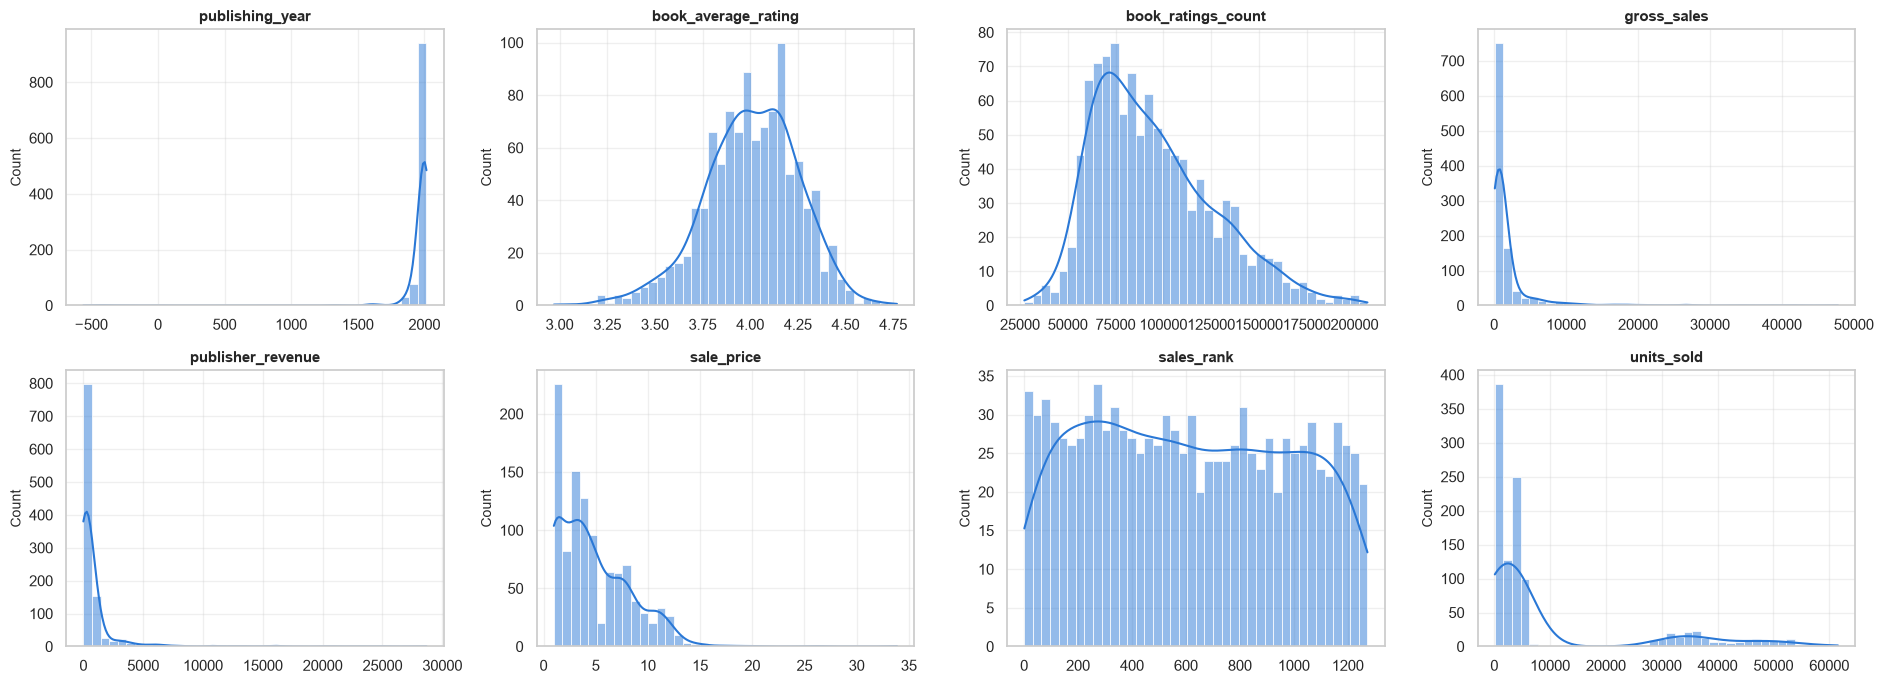

Libros con año anterior a 1455:
     publishing_year                                                                                         author
589             -560                                                               Aesop, Laura Harris, Laura Gibbs
990             -441                                                                         Sophocles, J.E. Thomas
293             -430                                                                         Sophocles, J.E. Thomas
241             -380                                                                             Plato, Desmond Lee
568             -300  Lao Tzu, Gia-Fu Feng, Jane English, Chungliang Al Huang, Rowena Pattee Kryder, Toinette Lippe
749              -17                                                                      Virgil, Robert Fitzgerald
636             1308                                             Dante Alighieri, Allen Mandelbaum, Eugenio Montale
446             1320                    

In [6]:
# ============================================================================
#  2.3 Distribuciones de las variables numéricas
# ============================================================================
fig, axes = plt.subplots(2, 4, figsize=(19, 7))
for ax, c in zip(np.ravel(axes), num_cols):
    sns.histplot(df_raw[c].dropna(), bins=40, kde=True, ax=ax, color=C_SERIE[0])
    ax.set_title(c, fontsize=11); ax.set_xlabel("")
plt.tight_layout(); plt.show()

print("Libros con año anterior a 1455:")
print(df_raw.loc[df_raw["publishing_year"] < 1455, ["publishing_year", "author"]]
      .astype({"publishing_year": int}).sort_values("publishing_year").to_string())

No hay filas duplicadas. Faltan valores en `language_code` (53 filas, 4.95 %), `book_name` (23, 2.15 %) y
`publishing_year` (1). Los 9 libros con año anterior a 1455, con un mínimo de −560, son obras clásicas de Esopo,
Sófocles, Platón, Lao Tse, Virgilio, Dante y Chaucer: el año corresponde a la composición de la obra y no a una
edición.

`units_sold`, `gross_sales` y `publisher_revenue` tienen una asimetría positiva marcada; en `units_sold` la media
es 9.677 y la mediana 3.924. Al menos el 25 % de los títulos tiene `publisher_revenue` igual a 0.

Entre las categóricas, `genre` mezcla `genre fiction` con `fiction` y `nonfiction`, `publisher` tiene tres
variantes de HarperCollins y `language_code` combina `eng` con `en-US`, `en-GB` y `en-CA`. `author` tiene 735
valores distintos en 1.070 libros.

---
## 3. Limpieza de datos

En esta etapa se corrigen errores (nulos en el identificador, grafías y codificación inconsistentes) y se toman
decisiones sobre filas y columnas. La imputación, la codificación y el escalado se hacen dentro del pipeline
(sección 5).

### 3.1 Funciones de limpieza

* `reparar_codificacion()` revierte el texto que la fuente guardó con doble codificación (`JosÃ©` → `José`), incluidos los
  bytes que cp1252 no define y que la fuente conservó como caracteres de control.
* `detectar_variantes_ortograficas()` compara, en minúsculas, todos los pares de valores únicos de una columna
  con `difflib.SequenceMatcher` (algoritmo de Ratcliff/Obershelp, similitud entre 0 y 1) y devuelve los pares
  con similitud ≥ 0.80. Descarta los pares cuyos números difieren (`Harry Potter 1` / `Harry Potter 2`). En
  `author` exige además la misma inicial de apellido y similitud ≥ 0.50 entre apellidos o, si el apellido
  coincide, la misma inicial del nombre (`E. L. James` / `P. D. James`).
* `construir_mapeo()` convierte los pares en un diccionario `{variante: canónico}`, con el valor más frecuente
  como canónico. Los mapeos aplicados se imprimen en 3.3.

In [7]:
# ============================================================================
#  3.1 Funciones de limpieza
# ============================================================================
BYTES_SIN_CP1252 = {0x81, 0x8D, 0x8F, 0x90, 0x9D}   # no definidos en cp1252: quedaron como U+0081, U+008D, ...

def reparar_codificacion(valor):
    '''Revierte texto UTF-8 decodificado como cp1252 ("JosÃ©" -> "José"); si no aplica, lo devuelve igual.'''
    if not isinstance(valor, str):
        return valor
    for _ in range(3):
        try:
            crudo = b"".join(bytes([ord(ch)]) if ord(ch) in BYTES_SIN_CP1252 else ch.encode("cp1252")
                             for ch in valor)
            nuevo = crudo.decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            break
        if nuevo == valor:
            break
        valor = nuevo
    return valor


def detectar_variantes_ortograficas(data: pd.DataFrame, columna: str,
                                    umbral_similitud: float = 0.80) -> pd.DataFrame:
    '''Pares de valores únicos de `columna` con similitud >= umbral.'''
    valores = data[columna].dropna().astype(str).str.strip().unique().tolist()
    pares = []
    for i in range(len(valores)):
        for j in range(i + 1, len(valores)):
            v1, v2 = valores[i], valores[j]
            if v1.lower() == v2.lower():
                pares.append({"Valor A": v1, "Valor B": v2, "Similitud": 1.0})
                continue
            # Números distintos: obras distintas (secuelas, volúmenes)
            if "".join(re.findall(r"\d+", v1)) != "".join(re.findall(r"\d+", v2)):
                continue
            # Autores: filtro por apellido e inicial del nombre
            if "author" in columna:
                p1, p2 = v1.split(), v2.split()
                if p1 and p2:
                    ap1, ap2 = p1[-1].lower(), p2[-1].lower()
                    if ap1 != ap2:
                        if ap1[0] != ap2[0] or difflib.SequenceMatcher(None, ap1, ap2).ratio() < 0.50:
                            continue
                    else:
                        n1 = re.sub(r"[^a-z]", "", " ".join(p1[:-1]).lower())
                        n2 = re.sub(r"[^a-z]", "", " ".join(p2[:-1]).lower())
                        if n1 and n2 and n1[0] != n2[0]:
                            continue
            ratio = difflib.SequenceMatcher(None, v1.lower(), v2.lower()).ratio()
            if ratio >= umbral_similitud:
                pares.append({"Valor A": v1, "Valor B": v2, "Similitud": ratio})
    return (pd.DataFrame(pares).sort_values("Similitud", ascending=False).reset_index(drop=True)
            if pares else pd.DataFrame(columns=["Valor A", "Valor B", "Similitud"]))


def construir_mapeo(pares: pd.DataFrame, data: pd.DataFrame, columna: str) -> dict:
    '''Diccionario {variante: canónico}; canónico = valor más frecuente. Resuelve cadenas A -> B -> C.'''
    if pares.empty:
        return {}
    frecuencias = data[columna].dropna().astype(str).str.strip().value_counts()
    mapeo = {}
    for _, row in pares.iterrows():
        a, b = row["Valor A"], row["Valor B"]
        canonico, variante = (a, b) if (frecuencias.get(a, 0), a) >= (frecuencias.get(b, 0), b) else (b, a)
        if variante in mapeo and frecuencias.get(mapeo[variante], 0) >= frecuencias.get(canonico, 0):
            continue
        mapeo[variante] = canonico

    def destino_final(valor):
        visitados = set()
        while valor in mapeo and mapeo[valor] != valor and valor not in visitados:
            visitados.add(valor)
            valor = mapeo[valor]
        return valor

    return {k: destino_final(k) for k in mapeo if destino_final(k) != k}

### 3.2 Criterios de limpieza

| Caso | Decisión | Motivo |
|---|---|---|
| Duplicados exactos | Eliminar | Duplican el peso de una fila y podrían quedar en entrenamiento y prueba a la vez. El archivo no tiene. |
| `publishing_year` < 1455 | Excluir la fila | Son obras de la Antigüedad y la Edad Media (Esopo, Sófocles, Platón, Dante, Chaucer, entre otras) cuyo año es el de composición, no el de una edición. El análisis se limita a obras posteriores a la imprenta en Europa; incluirlas daría antigüedades de hasta 2.586 años. |
| `publishing_year` nulo | Conservar | Se imputa con la mediana de entrenamiento dentro del pipeline. |
| `book_name` nulo | Eliminar la fila | Sin título el registro no es identificable. |
| Texto con doble codificación | Reparar | Afecta títulos y autores con caracteres no ASCII. |
| Variantes en `author` y `publisher` | Unificar | Una variante ortográfica no invalida el registro. En `publisher`, la división *HarperCollins Christian Publishing* se agrupa con *HarperCollins Publishers* porque el análisis es por grupo editorial. |
| Variantes en `book_name` | Unificar solo si comparten un par (autor, año) | Títulos parecidos del mismo autor en años distintos son obras o ediciones diferentes. |
| `language_code` | Eliminar la columna | Mezcla `eng` con variantes regionales (`en-US`, `en-GB`, `en-CA`) sin un criterio para recategorizar, y tiene 4.95 % de nulos. |
| `genre` | `genre fiction` → `fiction`, `nonfiction` → `non-fiction` | Vocabulario de cuatro valores, corregible a mano. |
| Valores de `genre`, `author_rating`, `publisher` | Minúsculas y `[a-z0-9_]` | Nombres legibles en las columnas One-Hot y un formato único para cargar casos nuevos (sección 12). |

Los valores atípicos de `units_sold` no se eliminan, porque corresponden a los superventas que se quiere
estudiar. En la regresión, su influencia se reduce con la transformación logarítmica (10.1).

### 3.3 Aplicación de la limpieza

In [8]:
# ============================================================================
#  3.3 Aplicación de la limpieza
# ============================================================================
df_clean = df_raw.drop_duplicates().reset_index(drop=True)
filas_iniciales = len(df_raw)

anterior_imprenta = df_clean["publishing_year"] < 1455
print(f"Obras anteriores a 1455 excluidas: {int(anterior_imprenta.sum())} | años nulos conservados: "
      f"{int(df_clean['publishing_year'].isna().sum())}")
df_clean = df_clean[~anterior_imprenta]

antes = len(df_clean)
df_clean = df_clean[df_clean["book_name"].notna()]
print(f"Filas sin book_name eliminadas: {antes - len(df_clean)}")

for c in ["book_name", "author"]:
    reparado = df_clean[c].map(reparar_codificacion)
    print(f"[{c}] valores con codificación reparada: {int((reparado != df_clean[c]).sum())}")
    df_clean[c] = reparado

mapeo_autores = construir_mapeo(detectar_variantes_ortograficas(df_clean, "author"), df_clean, "author")
df_clean["author"] = df_clean["author"].replace(mapeo_autores)
print(f"\n[author] variantes unificadas: {mapeo_autores}")

# Títulos: solo se unifican pares que comparten al menos un par (autor, año)
pares_libros = detectar_variantes_ortograficas(df_clean, "book_name")
autor_anio = (df_clean.dropna(subset=["publishing_year"])
              .assign(_par=lambda d: list(zip(d["author"], d["publishing_year"])))
              .groupby("book_name")["_par"].agg(set).to_dict())
comparten = [bool(autor_anio.get(a, set()) & autor_anio.get(b, set()))
             for a, b in zip(pares_libros["Valor A"], pares_libros["Valor B"])]
mapeo_libros = construir_mapeo(pares_libros[comparten], df_clean, "book_name")
df_clean["book_name"] = df_clean["book_name"].replace(mapeo_libros)
print(f"[book_name] pares similares: {len(pares_libros)} | con un par (autor, año) común: {sum(comparten)}")

df_clean = df_clean.drop(columns=["language_code"])
df_clean["genre"] = df_clean["genre"].replace({"genre fiction": "fiction", "nonfiction": "non-fiction"})

mapeo_publisher = construir_mapeo(detectar_variantes_ortograficas(df_clean, "publisher"), df_clean, "publisher")
df_clean["publisher"] = df_clean["publisher"].replace(mapeo_publisher)
print(f"[publisher] variantes unificadas: {mapeo_publisher}")

print("\nValores categóricos regularizados:")
for c in ["genre", "author_rating", "publisher"]:
    df_clean[c] = (df_clean[c].str.strip().str.lower()
                   .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
    print(f"   [{c}] {sorted(df_clean[c].unique())}")

df_clean = df_clean.reset_index(drop=True)
print(f"\nFilas: {filas_iniciales} -> {len(df_clean)} ({filas_iniciales - len(df_clean)} eliminadas)")

Obras anteriores a 1455 excluidas: 9 | años nulos conservados: 1
Filas sin book_name eliminadas: 23
[book_name] valores con codificación reparada: 38
[author] valores con codificación reparada: 23



[author] variantes unificadas: {'Haruki Murakami, Jay Rubin, Philip Gabriel': 'Haruki Murakami, Philip Gabriel', 'J. Lynn, Jennifer L. Armentrout': 'Jennifer L. Armentrout'}


[book_name] pares similares: 20 | con un par (autor, año) común: 0
[publisher] variantes unificadas: {'HarperCollins Publishing': 'HarperCollins Publishers', 'HarperCollins Christian Publishing': 'HarperCollins Publishers'}

Valores categóricos regularizados:
   [genre] ['children', 'fiction', 'non_fiction']
   [author_rating] ['excellent', 'famous', 'intermediate', 'novice']
   [publisher] ['amazon_digital_services_inc', 'hachette_book_group', 'harpercollins_publishers', 'macmillan', 'penguin_group_usa_llc', 'random_house_llc', 'simon_and_schuster_digital_sales_inc']

Filas: 1070 -> 1038 (32 eliminadas)


---
## 4. EDA sobre el dataset limpio y auditoría de integridad

### 4.1 Distribución de units_sold

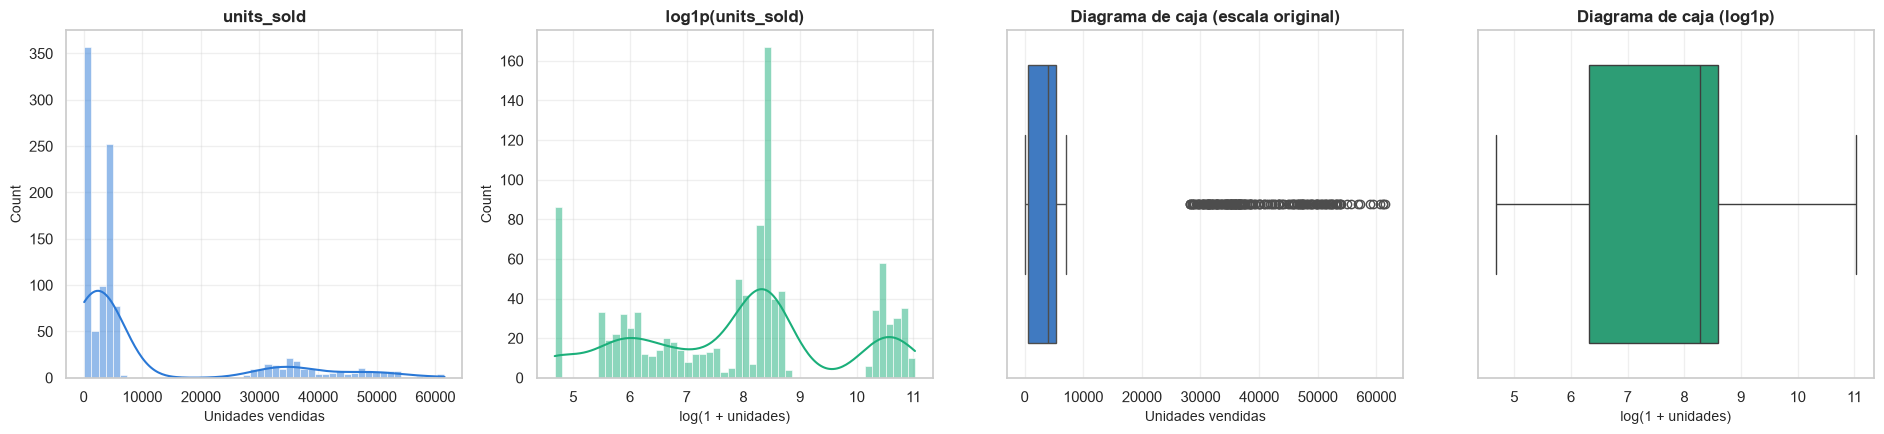

Asimetría: 1.738 | tras log1p: -0.033
Valores atípicos (1.5 IQR): 200 (19.3%) | tras log1p: 0


In [9]:
# ============================================================================
#  4.1 Distribución de units_sold
# ============================================================================
from scipy.stats import skew

def n_atipicos_iqr(s):
    q1, q3 = np.percentile(s, [25, 75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

unidades = df_clean["units_sold"]
log_unidades = np.log1p(unidades)

fig, ax = plt.subplots(1, 4, figsize=(19, 4.5))
sns.histplot(unidades, bins=50, kde=True, ax=ax[0], color=C_SERIE[0])
ax[0].set_title("units_sold"); ax[0].set_xlabel("Unidades vendidas")
sns.histplot(log_unidades, bins=50, kde=True, ax=ax[1], color=C_SERIE[2])
ax[1].set_title("log1p(units_sold)"); ax[1].set_xlabel("log(1 + unidades)")
sns.boxplot(x=unidades, ax=ax[2], color=C_SERIE[0])
ax[2].set_title("Diagrama de caja (escala original)"); ax[2].set_xlabel("Unidades vendidas")
sns.boxplot(x=log_unidades, ax=ax[3], color=C_SERIE[2])
ax[3].set_title("Diagrama de caja (log1p)"); ax[3].set_xlabel("log(1 + unidades)")
plt.tight_layout(); plt.show()

print(f"Asimetría: {skew(unidades):.3f} | tras log1p: {skew(log_unidades):.3f}")
print(f"Valores atípicos (1.5 IQR): {n_atipicos_iqr(unidades)} ({n_atipicos_iqr(unidades) / len(unidades):.1%})"
      f" | tras log1p: {n_atipicos_iqr(log_unidades)}")

### 4.2 Unidades vendidas por género

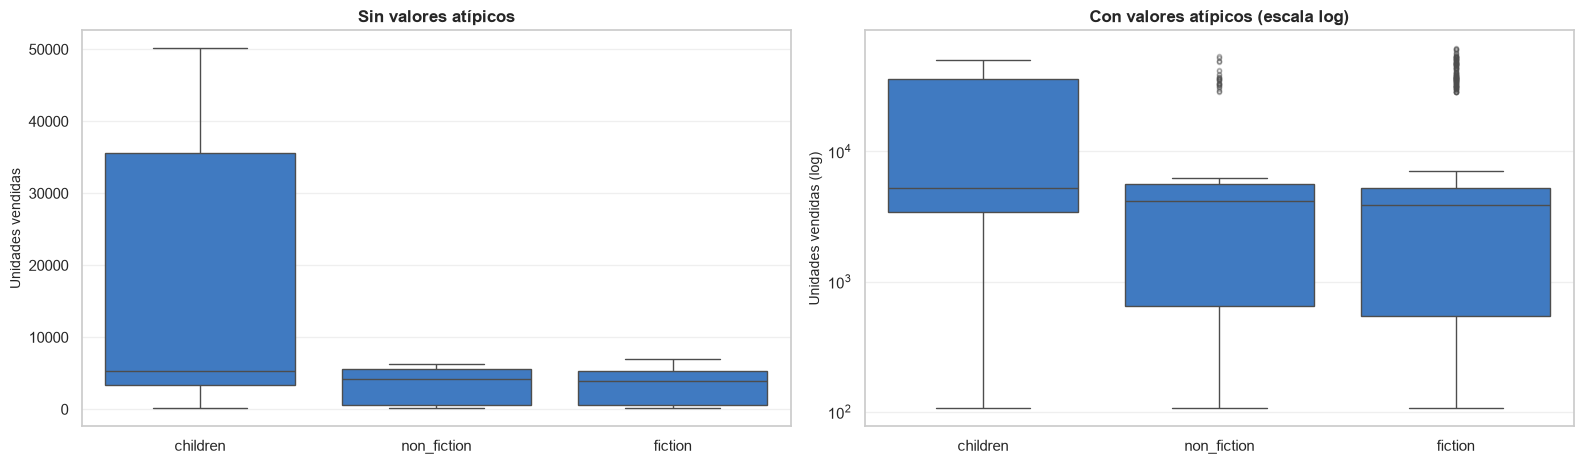

,libros,mediana,p95,atipicos
genre,,,,
children,15,"5,265.00","48,297.60",0
non_fiction,168,"4,185.00","38,728.80",34
fiction,855,"3,861.00","47,088.00",159


In [10]:
# ============================================================================
#  4.2 Unidades vendidas por género
# ============================================================================
orden = df_clean.groupby("genre")["units_sold"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
sns.boxplot(data=df_clean, x="genre", y="units_sold", order=orden, ax=ax[0], showfliers=False)
ax[0].set_title("Sin valores atípicos"); ax[0].set_xlabel(""); ax[0].set_ylabel("Unidades vendidas")
sns.boxplot(data=df_clean, x="genre", y="units_sold", order=orden, ax=ax[1],
            flierprops=dict(marker="o", markersize=3, alpha=.35))
ax[1].set_yscale("log"); ax[1].set_title("Con valores atípicos (escala log)")
ax[1].set_xlabel(""); ax[1].set_ylabel("Unidades vendidas (log)")
plt.tight_layout(); plt.show()

display(df_clean.groupby("genre")["units_sold"]
        .agg(libros="size", mediana="median", p95=lambda s: s.quantile(.95), atipicos=n_atipicos_iqr)
        .loc[orden])

`units_sold` tiene asimetría 1.74 y 200 valores atípicos según el criterio de 1.5 IQR (19.3 %). Con `log1p` la
asimetría baja a −0.03 y no quedan atípicos; esa es la escala que se usa en el experimento 2. Las medianas por
género (entre 3.861 y 5.265 unidades) difieren poco en comparación con la dispersión dentro de cada género, y
`children` tiene solo 15 libros. Estos datos todavía incluyen las dos poblaciones descriptas en 4.5.

### 4.3 Correlación de Spearman

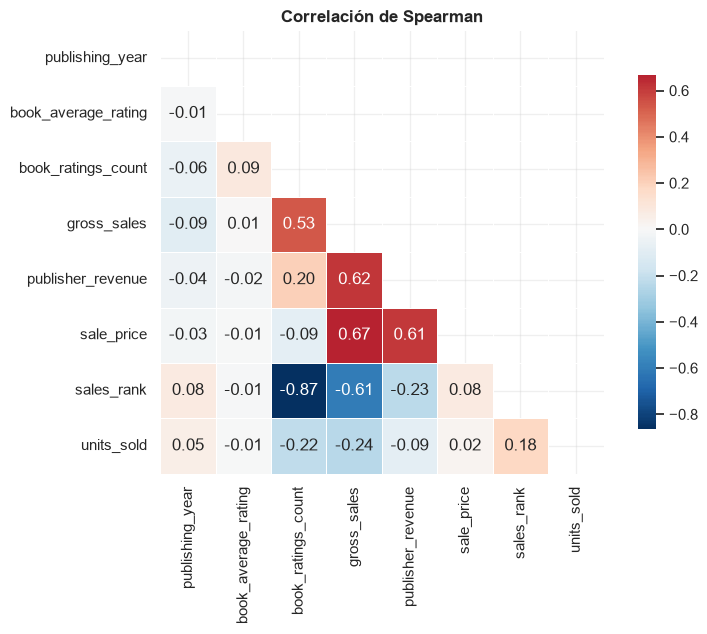

,Spearman con units_sold
gross_sales,-0.2391
book_ratings_count,-0.2222
sales_rank,0.1811
publisher_revenue,-0.0851
publishing_year,0.0534
sale_price,0.0233
book_average_rating,-0.0054


In [11]:
# ============================================================================
#  4.3 Correlación de Spearman
# ============================================================================
num_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
corr = df_clean[num_cols].corr(method="spearman")

plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, square=True, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Correlación de Spearman")
plt.tight_layout(); plt.show()

corr_units = corr["units_sold"].drop("units_sold").sort_values(key=abs, ascending=False)
display(corr_units.rename("Spearman con units_sold").to_frame())

Si `gross_sales` es unidades × precio y `sales_rank` ordena las ventas, ambas deberían correlacionar
fuertemente con `units_sold`. Las correlaciones observadas son débiles (−0.24 y +0.18) y la de `sales_rank` tiene
el signo contrario al esperado. La auditoría siguiente verifica esas relaciones.

### 4.4 Auditoría de integridad

| # | Relación esperada | Motivo |
|---|---|---|
| 1 | `gross_sales = units_sold × sale_price` | La facturación es precio por cantidad |
| 2 | `sales_rank` ordena inversamente a `units_sold` | Un ranking de ventas refleja las ventas |
| 3 | `publisher_revenue / gross_sales` es continua | El margen editorial depende del contrato, el formato y el autor |
| 4 | `units_sold` se asocia con algún atributo del libro (precio, calificaciones, año) | Algún atributo debería explicar parte de la venta |

,Resultado,Estado
Verificación,,
gross_sales = units_sold x sale_price,se cumple en 41.6% de las filas,FALLA
sales_rank ordena las ventas,Spearman con units_sold = +0.181 | con el orden de fila = +1.000,FALLA
margin_ratio es continuo,"valores distintos: [0.0, 0.6]",FALLA
units_sold se asocia con algún atributo del libro,|rho| máximo = 0.222 (book_ratings_count),FALLA


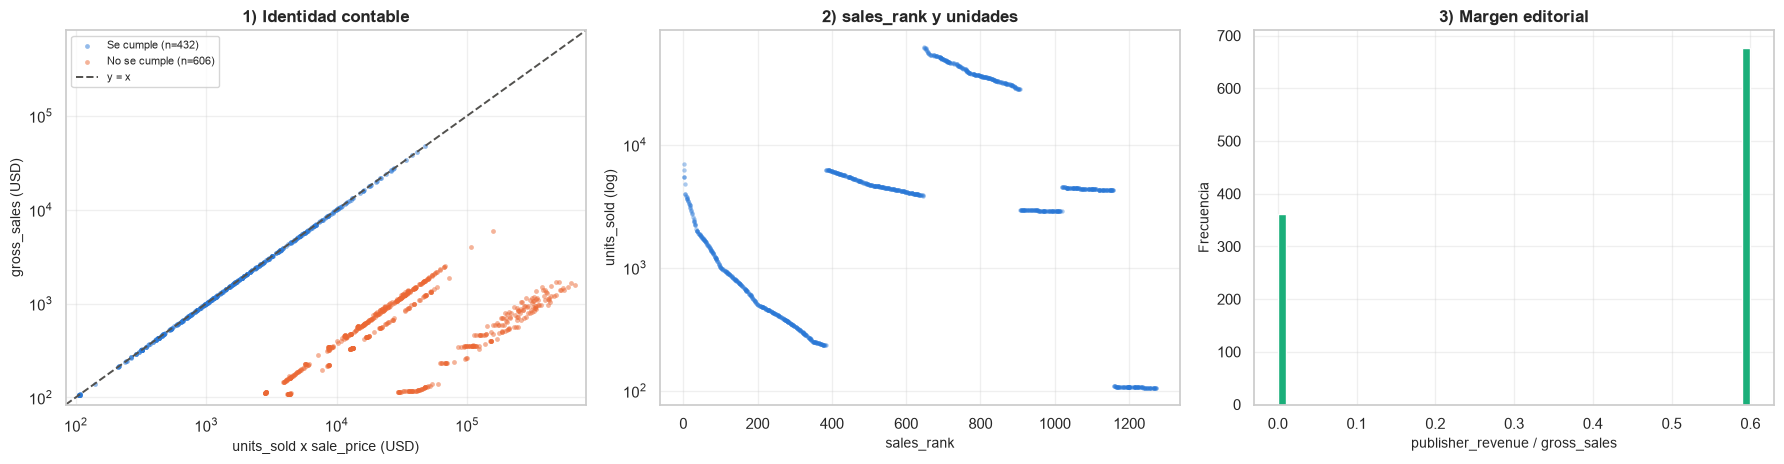

In [12]:
# ============================================================================
#  4.4 Auditoría de integridad
# ============================================================================
auditoria = []

# 1) Identidad contable (error relativo < 1 %)
implicito = df_clean["units_sold"] * df_clean["sale_price"]
err_rel   = (df_clean["gross_sales"] - implicito).abs() / df_clean["gross_sales"]
pct_ok    = float((err_rel < .01).mean())
auditoria.append({"Verificación": "gross_sales = units_sold x sale_price",
                  "Resultado": f"se cumple en {pct_ok:.1%} de las filas",
                  "Estado": "OK" if pct_ok > .95 else "FALLA"})

# 2) sales_rank frente a las ventas y frente al orden de las filas
rho_rank  = float(df_clean["sales_rank"].corr(df_clean["units_sold"], method="spearman"))
rho_orden = float(pd.Series(np.arange(len(df_clean))).corr(df_clean["sales_rank"], method="spearman"))
auditoria.append({"Verificación": "sales_rank ordena las ventas",
                  "Resultado": f"Spearman con units_sold = {rho_rank:+.3f} | con el orden de fila = {rho_orden:+.3f}",
                  "Estado": "OK" if rho_rank < -0.7 else "FALLA"})

# 3) Margen editorial (redondeo a 6 decimales para eliminar el error de punto flotante del cociente)
margen_aud = (df_clean["publisher_revenue"] / df_clean["gross_sales"]).round(6)
auditoria.append({"Verificación": "margin_ratio es continuo",
                  "Resultado": f"valores distintos: {sorted(margen_aud.unique().tolist())}",
                  "Estado": "OK" if margen_aud.nunique() > 10 else "FALLA"})

# 4) Asociación con atributos del libro (sin columnas de resultado)
atributos = ["sale_price", "book_average_rating", "book_ratings_count", "publishing_year"]
corr_attr = df_clean[atributos].corrwith(df_clean["units_sold"], method="spearman")
auditoria.append({"Verificación": "units_sold se asocia con algún atributo del libro",
                  "Resultado": f"|rho| máximo = {corr_attr.abs().max():.3f} ({corr_attr.abs().idxmax()})",
                  "Estado": "OK" if corr_attr.abs().max() > 0.30 else "FALLA"})

display(pd.DataFrame(auditoria).set_index("Verificación"))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
cumple = (err_rel < .01).values
ax[0].scatter(implicito[cumple], df_clean["gross_sales"][cumple], s=12, alpha=.5, color=C_SERIE[0],
              linewidths=0, label=f"Se cumple (n={cumple.sum()})")
ax[0].scatter(implicito[~cumple], df_clean["gross_sales"][~cumple], s=12, alpha=.5, color=C_SERIE[1],
              linewidths=0, label=f"No se cumple (n={(~cumple).sum()})")
lim = [min(implicito.min(), df_clean["gross_sales"].min()) * .8, max(implicito.max(), df_clean["gross_sales"].max()) * 1.2]
ax[0].plot(lim, lim, ls="--", lw=1.4, color=C_REF, label="y = x")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("units_sold x sale_price (USD)"); ax[0].set_ylabel("gross_sales (USD)")
ax[0].set_title("1) Identidad contable"); ax[0].legend(fontsize=8, loc="upper left")
ax[1].scatter(df_clean["sales_rank"], df_clean["units_sold"], s=10, alpha=.4, color=C_SERIE[0], linewidths=0)
ax[1].set_yscale("log"); ax[1].set_xlabel("sales_rank"); ax[1].set_ylabel("units_sold (log)")
ax[1].set_title("2) sales_rank y unidades")
ax[2].hist(margen_aud, bins=60, color=C_SERIE[2])
ax[2].set_xlabel("publisher_revenue / gross_sales"); ax[2].set_ylabel("Frecuencia")
ax[2].set_title("3) Margen editorial")
plt.tight_layout(); plt.show()

### 4.5 El archivo contiene dos poblaciones

Las cuatro verificaciones fallan. El panel 1 muestra dos grupos de filas: en el bloque A la identidad
`gross_sales = units_sold × sale_price` se cumple (error relativo < 1 %); en el bloque B no se cumple y no es
posible determinar cuál de los tres valores es erróneo. Además, sobre el archivo completo `sales_rank` tiene
correlación +1.000 con el orden de las filas (el archivo está ordenado por ese ranking) y el margen editorial
toma solo los valores 0 y 0.6.

Si el umbral de superventas se calculara sobre el archivo completo, casi todos los positivos provendrían del
bloque B y la etiqueta identificaría el bloque de origen en lugar de una propiedad del libro. Por eso el
análisis se restringe al bloque A. `gross_sales`, `publisher_revenue` y `sales_rank` se usan solo para este
diagnóstico y para definir objetivos.

### 4.6 Recorte al bloque A

,filas,unidades_mediana,unidades_p80,precio_mediano
bloque,,,,
A,432,430.50,"1,169.00",3.9900
B,606,"4,617.00","35,640.00",3.9900


P80 de units_sold en el archivo completo: 6,183
Proporción de superventas con ese corte: bloque A 0.5% | bloque B 34.2%

Recorte: 1038 -> 432 filas (58.4% descartadas)
Nulos en df_modelo: ninguno
Asimetría de units_sold en el bloque A: 2.83 | tras log1p: 0.23

Correlación de Spearman con units_sold:


,Archivo completo,Bloque A,Bloque B
sales_rank,0.1811,-0.9996,-0.3228
book_ratings_count,-0.2222,0.8344,0.2293
gross_sales,-0.2391,0.7131,0.0276
publisher_revenue,-0.0851,0.2313,0.0088
sale_price,0.0233,-0.1117,-0.0233
publishing_year,0.0534,-0.0786,-0.0049
book_average_rating,-0.0054,0.0219,-0.0419


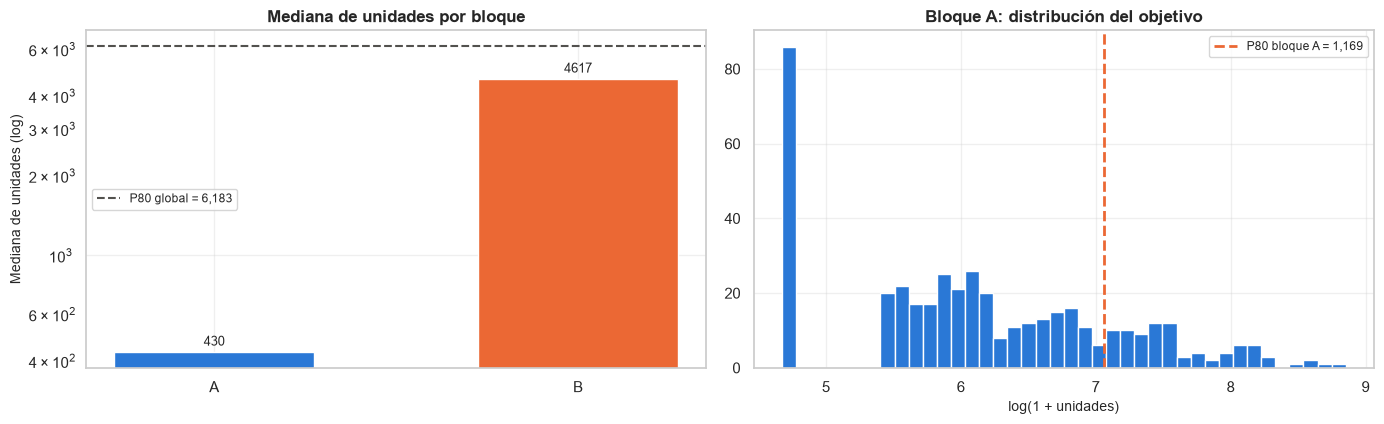

In [13]:
# ============================================================================
#  4.6 Recorte al bloque A
# ============================================================================
TOL_IDENTIDAD = 0.01
es_bloque_a = err_rel < TOL_IDENTIDAD
bloque = np.where(es_bloque_a, "A", "B")

resumen_bloques = (df_clean.assign(bloque=bloque).groupby("bloque")
                   .agg(filas=("units_sold", "size"),
                        unidades_mediana=("units_sold", "median"),
                        unidades_p80=("units_sold", lambda s: s.quantile(.80)),
                        precio_mediano=("sale_price", "median")))
display(resumen_bloques)

p80_global = df_clean["units_sold"].quantile(.80)
tasa = (df_clean["units_sold"] >= p80_global).groupby(bloque).mean()
print(f"P80 de units_sold en el archivo completo: {p80_global:,.0f}")
print(f"Proporción de superventas con ese corte: bloque A {tasa['A']:.1%} | bloque B {tasa['B']:.1%}")

df_modelo = df_clean[es_bloque_a].reset_index(drop=True)
print(f"\nRecorte: {len(df_clean)} -> {len(df_modelo)} filas ({1 - len(df_modelo) / len(df_clean):.1%} descartadas)")
print(f"Nulos en df_modelo: {df_modelo.isna().sum()[lambda s: s > 0].to_dict() or 'ninguno'}")
print(f"Asimetría de units_sold en el bloque A: {skew(df_modelo['units_sold']):.2f} "
      f"| tras log1p: {skew(np.log1p(df_modelo['units_sold'])):.2f}")

numericas = [c for c in num_cols if c != "units_sold"]
corr_bloques = pd.DataFrame({
    "Archivo completo": corr_units,
    "Bloque A": df_modelo[numericas].corrwith(df_modelo["units_sold"], method="spearman"),
    "Bloque B": df_clean.loc[~es_bloque_a, numericas].corrwith(df_clean.loc[~es_bloque_a, "units_sold"], method="spearman"),
}).sort_values("Bloque A", key=abs, ascending=False)
print("\nCorrelación de Spearman con units_sold:")
display(corr_bloques)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
ax[0].bar(resumen_bloques.index, resumen_bloques["unidades_mediana"], color=C_SERIE[:2], width=.55)
ax[0].bar_label(ax[0].containers[0], fmt="%.0f", padding=3, fontsize=9)
ax[0].axhline(p80_global, color=C_REF, ls="--", lw=1.5, label=f"P80 global = {p80_global:,.0f}")
ax[0].set_yscale("log"); ax[0].set_ylabel("Mediana de unidades (log)")
ax[0].set_title("Mediana de unidades por bloque"); ax[0].legend(fontsize=8.5)
ax[1].hist(np.log1p(df_modelo["units_sold"]), bins=40, color=C_SERIE[0])
ax[1].axvline(np.log1p(df_modelo["units_sold"].quantile(.80)), color=C_SERIE[1], ls="--", lw=2,
              label=f"P80 bloque A = {df_modelo['units_sold'].quantile(.80):,.0f}")
ax[1].set_title("Bloque A: distribución del objetivo")
ax[1].set_xlabel("log(1 + unidades)"); ax[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

El bloque A (432 libros) tiene una mediana de 430 unidades y el bloque B (606 libros), de 4.617, con el mismo
precio mediano (USD 3.99). Con el percentil 80 del archivo completo (6.183 unidades) solo el 0.5 % del bloque A
sería superventas, contra el 34.2 % del bloque B.

Las correlaciones de `book_ratings_count` y `sales_rank` con `units_sold` tienen el mismo signo en los dos
bloques y lo invierten al combinarlos, un caso de paradoja de Simpson: `book_ratings_count` vale +0.83 en A,
+0.23 en B y −0.22 en el archivo completo; `sales_rank`, −0.9996, −0.32 y +0.18. Las correlaciones de 4.3
reflejaban la mezcla de poblaciones.

En el bloque A, `sales_rank` es prácticamente una función de `units_sold` y `gross_sales` es
`units_sold × sale_price`, por lo que ambas quedan fuera de las predictoras. El bloque A no tiene nulos (el único
año faltante estaba en el bloque B); los imputadores del pipeline se mantienen para datos nuevos.

---
## 5. Transformaciones

### 5.1 Variables derivadas

| Variable | Definición | Motivo |
|---|---|---|
| `book_age` | 2026 − `publishing_year` | Antigüedad en años. Es una transformación lineal del año, por lo que no agrega información a los modelos; se usa por legibilidad y reemplaza a `publishing_year`. |
| `price_relative_to_genre` | `sale_price` / precio medio del género | Posición del precio respecto de su género. |
| `social_proof_score` | `book_average_rating` × log(1 + `book_ratings_count`) | Interacción entre calificación y volumen de calificaciones; el logaritmo reduce la influencia de los valores grandes. |

El precio medio por género se estima a partir de los datos. Para que provenga solo del conjunto de
entrenamiento, las tres variables se calculan en un transformador propio, `IngenieriaFeatures`, que aprende esas
medias en `fit()` y forma parte del pipeline.

,count,mean,std,min,25%,50%,75%,max
book_age,432.00,44.8843,60.2172,10.0000,17.0000,26.0000,46.0000,433.00
price_relative_to_genre,432.00,1.0000,0.7802,0.2131,0.4286,0.8597,1.3984,7.2956
social_proof_score,432.00,46.4589,3.3312,34.2460,44.3592,46.5558,48.8223,55.1384


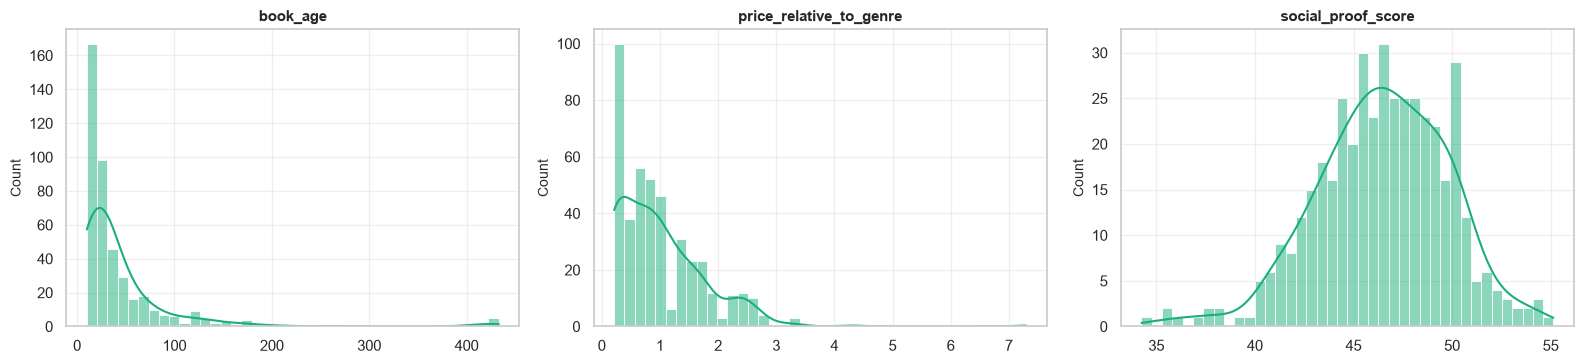

In [14]:
# ============================================================================
#  5.1 Transformador de variables derivadas
# ============================================================================
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone

class IngenieriaFeatures(TransformerMixin, BaseEstimator):
    '''Crea book_age, price_relative_to_genre y social_proof_score. Aprende en fit() el precio medio por género.'''
    def __init__(self, anio_referencia: int = 2026):
        self.anio_referencia = anio_referencia

    def fit(self, X, y=None):
        self.media_por_genero_ = X.groupby("genre")["sale_price"].mean().to_dict()
        self.media_global_     = float(X["sale_price"].mean())
        return self

    def transform(self, X):
        out = X.copy()
        out["book_age"] = self.anio_referencia - out["publishing_year"]
        medias = out["genre"].map(self.media_por_genero_).astype(float).fillna(self.media_global_)
        out["price_relative_to_genre"] = out["sale_price"] / medias
        out["social_proof_score"] = out["book_average_rating"] * np.log1p(out["book_ratings_count"])
        return out.drop(columns=["publishing_year"])

# Vista descriptiva sobre todo el bloque A; los modelos usan la versión ajustada con entrenamiento
nuevas = ["book_age", "price_relative_to_genre", "social_proof_score"]
vista = IngenieriaFeatures().fit_transform(df_modelo)
display(vista[nuevas].describe().T)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, c in zip(ax, nuevas):
    sns.histplot(vista[c], bins=40, kde=True, ax=a, color=C_SERIE[2])
    a.set_title(c, fontsize=11); a.set_xlabel("")
plt.tight_layout(); plt.show()

### 5.2 Codificación, imputación y escalado

* **One-Hot** para `author_rating` (4 niveles), `genre` (3) y `publisher` (7). Las categorías de
  `author_rating` sugieren un orden, pero la fuente no lo define (por ejemplo, entre `famous` y `excellent`), y
  One-Hot no supone ninguno. Con `handle_unknown="ignore"` el pipeline acepta categorías no vistas.
* **Codificación por objetivo** (*target encoding*) para `author` (341 autores en el bloque A). `TargetEncoder`
  reemplaza cada autor por la media del objetivo, suavizada hacia la media global según la cantidad de libros del
  autor. Durante el ajuste usa validación cruzada interna: el valor de cada fila se calcula con las otras
  particiones, sin su propio objetivo.
* **Imputación** por mediana (numéricas) y moda (categóricas).
* **Escalado** con `StandardScaler`. SVM y Ridge dependen de la escala de las variables y los árboles no; por
  eso se usa el mismo preprocesamiento para todos los modelos.

In [15]:
# ============================================================================
#  5.2 Preprocesamiento y pipeline
# ============================================================================
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder

COLS_NUM = ["sale_price", "book_age", "price_relative_to_genre",
            "book_average_rating", "book_ratings_count", "social_proof_score"]
COLS_OHE = ["author_rating", "genre", "publisher"]
COLS_TE  = ["author"]

def construir_preprocesamiento(cols_num=COLS_NUM):
    return ColumnTransformer(
        transformers=[
            ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                              ("escalar", StandardScaler())]), cols_num),
            ("ohe", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                              ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), COLS_OHE),
            ("te",  Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                              ("codificar", TargetEncoder(random_state=RANDOM_STATE)),
                              ("escalar", StandardScaler())]), COLS_TE),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

def construir_pipeline(modelo, cols_num=COLS_NUM):
    '''Variables derivadas -> preprocesamiento -> modelo.'''
    return Pipeline([
        ("features", IngenieriaFeatures()),
        ("prep",     construir_preprocesamiento(cols_num)),
        ("modelo",   modelo),
    ])

---
## 6. Selección de variables

Una variable se usa como predictora solo si su valor está disponible cuando se toma la decisión. Las decisiones
consideradas se refieren a títulos ya publicados (reimpresión, campañas, contratos), para los que las
calificaciones de los lectores ya existen. Se excluyen el objetivo, las columnas derivadas de la venta y los
identificadores. En una decisión de lanzamiento no habría calificaciones; la sección 9.7 mide el efecto de
excluirlas.

### 6.1 Variables de entrada y excluidas

In [16]:
# ============================================================================
#  6.1 Variables de entrada y excluidas
# ============================================================================
COLUMNAS_ENTRADA = ["author", "author_rating", "genre", "publisher", "sale_price", "publishing_year",
                    "book_average_rating", "book_ratings_count"]
EXCLUIDAS = {
    "units_sold"       : "Objetivo de los experimentos 1 y 2",
    "gross_sales"      : "En el bloque A es units_sold x sale_price (fuga de información)",
    "publisher_revenue": "Define el objetivo del experimento 3",
    "sales_rank"       : f"En el bloque A es función de units_sold (Spearman {corr_bloques.loc['sales_rank', 'Bloque A']:+.4f})",
    "book_name"        : "Identificador del libro",
}

display(pd.DataFrame(
    [{"Columna": c, "Se usa": "sí", "Motivo": "Disponible para un título publicado"} for c in COLUMNAS_ENTRADA] +
    [{"Columna": c, "Se usa": "no", "Motivo": m} for c, m in EXCLUIDAS.items()]
).set_index("Columna"))

sin_clasificar = set(df_modelo.columns) - set(COLUMNAS_ENTRADA) - set(EXCLUIDAS)
assert not sin_clasificar, f"Columnas sin clasificar: {sin_clasificar}"

,Se usa,Motivo
Columna,,
author,sí,Disponible para un título publicado
author_rating,sí,Disponible para un título publicado
genre,sí,Disponible para un título publicado
publisher,sí,Disponible para un título publicado
sale_price,sí,Disponible para un título publicado
publishing_year,sí,Disponible para un título publicado
book_average_rating,sí,Disponible para un título publicado
book_ratings_count,sí,Disponible para un título publicado
units_sold,no,Objetivo de los experimentos 1 y 2


---
## 7. Objetivos y división en entrenamiento y prueba

Los tres objetivos se definen sobre el bloque A:

* Experimento 1: `is_bestseller` = 1 si `units_sold` ≥ percentil 80. El percentil se calcula sobre todo el
  bloque A; define la etiqueta y no interviene en las variables de entrada.
* Experimento 2: log(1 + `units_sold`) (10.1).
* Experimento 3: `genera_ingreso` = 1 si `publisher_revenue` > 0 (11.1).

Se hace una única división 70/30 para los tres experimentos, estratificada por la combinación de las dos
etiquetas binarias.

### 7.1 Objetivos y división

In [17]:
# ============================================================================
#  7.1 Objetivos y división
# ============================================================================
from sklearn.model_selection import train_test_split

UMBRAL_BESTSELLER = df_modelo["units_sold"].quantile(0.80)

X = df_modelo[COLUMNAS_ENTRADA].copy()
objetivos = pd.DataFrame({
    "is_bestseller" : (df_modelo["units_sold"] >= UMBRAL_BESTSELLER).astype(int),
    "log_units"     : np.log1p(df_modelo["units_sold"]),
    "genera_ingreso": (df_modelo["publisher_revenue"] > 0).astype(int),
})

estrato = objetivos["is_bestseller"].astype(str) + "_" + objetivos["genera_ingreso"].astype(str)
print("Estratos (is_bestseller_genera_ingreso):", estrato.value_counts().to_dict())

idx_train, idx_test = train_test_split(df_modelo.index, test_size=TEST_SIZE,
                                       random_state=RANDOM_STATE, stratify=estrato)
X_train, X_test = X.loc[idx_train], X.loc[idx_test]
y1_tr, y1_te = objetivos.loc[idx_train, "is_bestseller"],  objetivos.loc[idx_test, "is_bestseller"]
y2_tr, y2_te = objetivos.loc[idx_train, "log_units"],      objetivos.loc[idx_test, "log_units"]
y3_tr, y3_te = objetivos.loc[idx_train, "genera_ingreso"], objetivos.loc[idx_test, "genera_ingreso"]

print(f"Umbral de superventas: {UMBRAL_BESTSELLER:,.0f} unidades | entrenamiento {X_train.shape} | prueba {X_test.shape}")
display(pd.DataFrame({"Entrenamiento": [y1_tr.mean(), y2_tr.mean(), y3_tr.mean()],
                      "Prueba"       : [y1_te.mean(), y2_te.mean(), y3_te.mean()]},
                     index=["proporción de superventas", "media de log1p(units)", "proporción con ingreso editorial"]))

Estratos (is_bestseller_genera_ingreso): {'0_1': 221, '0_0': 123, '1_1': 50, '1_0': 38}
Umbral de superventas: 1,169 unidades | entrenamiento (302, 8) | prueba (130, 8)


,Entrenamiento,Prueba
proporción de superventas,0.2053,0.2000
media de log1p(units),6.1489,6.1177
proporción con ingreso editorial,0.6258,0.6308


### 7.2 Preprocesamiento ajustado con entrenamiento

In [18]:
# ============================================================================
#  7.2 Preprocesamiento ajustado con entrenamiento
# ============================================================================
prep_demo = Pipeline([("features", IngenieriaFeatures()), ("prep", construir_preprocesamiento())])
Xt_demo = prep_demo.fit_transform(X_train, y1_tr)       # TargetEncoder necesita el objetivo
print(f"{X_train.shape[1]} columnas de entrada -> {Xt_demo.shape[1]} variables:")
print(list(prep_demo.named_steps["prep"].get_feature_names_out()))
print("Precio medio por género (entrenamiento):",
      {k: round(v, 2) for k, v in prep_demo.named_steps["features"].media_por_genero_.items()})

8 columnas de entrada -> 21 variables:
['sale_price', 'book_age', 'price_relative_to_genre', 'book_average_rating', 'book_ratings_count', 'social_proof_score', 'author_rating_excellent', 'author_rating_famous', 'author_rating_intermediate', 'author_rating_novice', 'genre_children', 'genre_fiction', 'genre_non_fiction', 'publisher_amazon_digital_services_inc', 'publisher_hachette_book_group', 'publisher_harpercollins_publishers', 'publisher_macmillan', 'publisher_penguin_group_usa_llc', 'publisher_random_house_llc', 'publisher_simon_and_schuster_digital_sales_inc', 'author']
Precio medio por género (entrenamiento): {'children': 6.07, 'fiction': 4.37, 'non_fiction': 4.4}


---
# Parte II: modelado y evaluación (Entrega Final)

## 8. Modelos y estrategia de evaluación

### 8.1 Modelos

| Experimento | Tipo | Modelos | Justificación |
|---|---|---|---|
| 1 | Clasificación binaria desbalanceada | `DummyClassifier` (referencia), `XGBClassifier` | El boosting de árboles modela relaciones no lineales e interacciones sin especificarlas; el desbalance se trata con `scale_pos_weight`. |
| 2 | Regresión | `DummyRegressor` (referencia), `Ridge`, `XGBRegressor`, `LGBMRegressor` | Ridge es un modelo lineal regularizado; XGBoost y LightGBM son dos implementaciones de boosting que difieren en cómo crecen los árboles (por niveles y por hojas). |
| 3 | Clasificación binaria | `DummyClassifier` y regla por editorial (referencias), `SVC` lineal y RBF, `RandomForestClassifier` | Frontera lineal, frontera no lineal suave (kernel RBF) y particiones paralelas a los ejes (Random Forest). La regla por editorial se explica en 11.1. |

### 8.2 Estrategia

1. Un modelo de referencia por experimento.
2. Validación cruzada de 5 particiones sobre el conjunto de entrenamiento (estratificada en clasificación), con
   `GridSearchCV` sobre el pipeline completo, de modo que el preprocesamiento se ajusta dentro de cada partición.
3. Puntajes de entrenamiento y de validación (`return_train_score=True`) para detectar sobreajuste.
4. Regla de un error estándar para elegir hiperparámetros y modelos: entre las opciones cuyo puntaje medio de
   validación está a menos de un error estándar (desvío entre particiones / √5) de la mejor, se elige la menos
   compleja. El orden de complejidad de cada modelo se define en 8.4.
5. Una única evaluación en el conjunto de prueba con el modelo elegido.

### 8.3 Métricas

* Experimento 1: área bajo la curva precisión-sensibilidad (PR-AUC) para seleccionar. Su valor de referencia es
  la prevalencia (0.20). Se informan también ROC-AUC, F1, precisión y sensibilidad. La exactitud no se usa,
  porque predecir siempre la clase negativa da 0.80.
* Experimento 2: RMSE para seleccionar, y MAE y R² como complemento, en escala logarítmica y en unidades.
* Experimento 3: exactitud balanceada (promedio de la sensibilidad de ambas clases; 0.5 para un clasificador
  constante) para seleccionar. F1 no es adecuada para seleccionar en este caso: con 63 % de positivos, predecir
  siempre "con ingreso" da F1 = 0.77. Se informan también ROC-AUC y F1.

### 8.4 Funciones de evaluación y orden de complejidad

In [19]:
# ============================================================================
#  8.4 Funciones de evaluación y orden de complejidad
# ============================================================================
from sklearn.model_selection import StratifiedKFold, KFold, GridSearchCV, cross_validate, cross_val_predict

N_FOLDS = 5
CV_CLF = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
CV_REG = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Orden de complejidad: claves menores = modelo más simple
def complejidad_boosting(p):
    # profundidad u hojas, pasos efectivos (árboles x tasa de aprendizaje) y regularización
    return (p.get("modelo__max_depth", 0), p.get("modelo__num_leaves", 0),
            p["modelo__n_estimators"] * p["modelo__learning_rate"],
            -p.get("modelo__min_child_weight", 0), -p.get("modelo__min_child_samples", 0),
            -p.get("modelo__reg_lambda", 0))

def complejidad_ridge(p):
    return -p["modelo__alpha"]

def complejidad_svm(p):
    return (p["modelo__C"], p.get("modelo__gamma", 0))

def complejidad_rf(p):
    return (-p["modelo__min_samples_leaf"], p["modelo__max_depth"] or 1_000)


def refit_un_error_estandar(metrica, complejidad):
    '''Índice de la combinación menos compleja cuyo puntaje medio de validación está a menos de un
    error estándar del mejor.'''
    def _elegir(r):
        media = np.asarray(r[f"mean_test_{metrica}"], dtype=float)
        mejor = int(np.nanargmax(media))
        umbral = media[mejor] - r[f"std_test_{metrica}"][mejor] / np.sqrt(N_FOLDS)
        candidatas = np.flatnonzero(media >= umbral)
        return int(min(candidatas, key=lambda i: (complejidad(r["params"][i]), -media[i])))
    return _elegir


def buscar(nombre, estimador, grilla, X, y, cv, scoring, refit, complejidad=lambda p: 0):
    gs = GridSearchCV(estimador, grilla, scoring=scoring, refit=refit_un_error_estandar(refit, complejidad),
                      cv=cv, n_jobs=-1, return_train_score=True)
    gs.fit(X, y)
    r, i = gs.cv_results_, gs.best_index_
    s = -1 if scoring[refit].startswith("neg_") else 1   # scikit-learn maximiza el error con signo negativo
    print(f"[{nombre}] {len(r['params'])} combinaciones | mejor {refit} val = {s * np.max(r[f'mean_test_{refit}']):.4f} | "
          f"elegida: val = {s * r[f'mean_test_{refit}'][i]:.4f}, entr = {s * r[f'mean_train_{refit}'][i]:.4f}")
    return gs


def fila_cv(nombre, gs, metricas, negativas=()):
    '''Media en entrenamiento y validación, y desvío en validación, de la combinación elegida.'''
    r, i = gs.cv_results_, gs.best_index_
    fila = {"Modelo": nombre}
    for m in metricas:
        s = -1 if m in negativas else 1
        fila[f"{m} entr"] = s * r[f"mean_train_{m}"][i]
        fila[f"{m} val"]  = s * r[f"mean_test_{m}"][i]
        fila[f"{m} ±"]    = r[f"std_test_{m}"][i]
    return fila


def elegir_modelo(tabla, metrica, orden_simplicidad, mayor_es_mejor=True):
    '''Regla de un error estándar entre modelos: el primero de `orden_simplicidad` a menos de un
    error estándar del mejor.'''
    val = tabla.loc[orden_simplicidad, f"{metrica} val"]
    ee  = tabla.loc[orden_simplicidad, f"{metrica} ±"] / np.sqrt(N_FOLDS)
    mejor = val.idxmax() if mayor_es_mejor else val.idxmin()
    dentro = val >= val[mejor] - ee[mejor] if mayor_es_mejor else val <= val[mejor] + ee[mejor]
    return dentro[dentro].index[0]

---
## 9. Experimento 1: clasificación de superventas con XGBoost

¿Un libro ya publicado, con su precio, editorial, género, autor y calificaciones, pertenece al quintil superior
de ventas? La etiqueta se construye con las ventas históricas y el modelo estima su probabilidad a partir de
atributos observables. `units_sold` y las columnas derivadas de ella no forman parte de X.

### 9.1 Referencia y búsqueda de hiperparámetros

In [20]:
# ============================================================================
#  9.1 Referencia y búsqueda de hiperparámetros
# ============================================================================
from sklearn.dummy import DummyClassifier
from xgboost import XGBClassifier

SCORING_1 = {"PR-AUC": "average_precision", "ROC-AUC": "roc_auc", "F1": "f1",
             "Precisión": "precision", "Sensibilidad": "recall"}

# Referencia: predice la clase mayoritaria con probabilidad igual a la prevalencia
gs1_ref = buscar("Referencia", construir_pipeline(DummyClassifier(strategy="prior")),
                 {"modelo__strategy": ["prior"]}, X_train, y1_tr, CV_CLF, SCORING_1, "PR-AUC")

SCALE_POS_WEIGHT = float((y1_tr == 0).sum() / (y1_tr == 1).sum())
xgb_clf = XGBClassifier(objective="binary:logistic", eval_metric="aucpr", scale_pos_weight=SCALE_POS_WEIGHT,
                        subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                        random_state=RANDOM_STATE, n_jobs=1)
grilla_xgb1 = {
    "modelo__n_estimators"    : [150, 300],
    "modelo__max_depth"       : [2, 3, 4],
    "modelo__learning_rate"   : [0.05, 0.1],
    "modelo__min_child_weight": [1, 5],
    "modelo__reg_lambda"      : [1, 10],
}
gs1_xgb = buscar("XGBoost", construir_pipeline(xgb_clf), grilla_xgb1, X_train, y1_tr, CV_CLF,
                 SCORING_1, "PR-AUC", complejidad_boosting)
print(f"\nscale_pos_weight = {SCALE_POS_WEIGHT:.3f}")
print("Hiperparámetros elegidos:", gs1_xgb.best_params_)

resultados_1 = pd.DataFrame(gs1_xgb.cv_results_).sort_values("rank_test_PR-AUC")
columnas = ["params", "mean_test_PR-AUC", "std_test_PR-AUC", "mean_train_PR-AUC"]
print("\nCinco combinaciones con mayor PR-AUC de validación:")
display(resultados_1[columnas].head(5))
print("Combinación elegida:")
display(resultados_1.loc[[gs1_xgb.best_index_], columnas])

[Referencia] 1 combinaciones | mejor PR-AUC val = 0.2052 | elegida: val = 0.2052, entr = 0.2053


[XGBoost] 48 combinaciones | mejor PR-AUC val = 0.7374 | elegida: val = 0.7169, entr = 0.8387

scale_pos_weight = 3.871
Hiperparámetros elegidos: {'modelo__learning_rate': 0.05, 'modelo__max_depth': 2, 'modelo__min_child_weight': 5, 'modelo__n_estimators': 150, 'modelo__reg_lambda': 10}

Cinco combinaciones con mayor PR-AUC de validación:


,params,mean_test_PR-AUC,std_test_PR-AUC,mean_train_PR-AUC
40,"{'modelo__learning_rate': 0.1, 'modelo__max_depth': 4, 'modelo__min_child_we...",0.7374,0.1128,1.0000
20,"{'modelo__learning_rate': 0.05, 'modelo__max_depth': 4, 'modelo__min_child_w...",0.7344,0.1163,0.9530
36,"{'modelo__learning_rate': 0.1, 'modelo__max_depth': 3, 'modelo__min_child_we...",0.7342,0.1147,0.9677
12,"{'modelo__learning_rate': 0.05, 'modelo__max_depth': 3, 'modelo__min_child_w...",0.7340,0.1101,0.9437
42,"{'modelo__learning_rate': 0.1, 'modelo__max_depth': 4, 'modelo__min_child_we...",0.7331,0.1072,1.0000


Combinación elegida:


,params,mean_test_PR-AUC,std_test_PR-AUC,mean_train_PR-AUC
5,"{'modelo__learning_rate': 0.05, 'modelo__max_depth': 2, 'modelo__min_child_w...",0.7169,0.1064,0.8387


### 9.2 Validación cruzada y sobreajuste

,PR-AUC entr,PR-AUC val,PR-AUC ±,ROC-AUC entr,ROC-AUC val,ROC-AUC ±,F1 entr,F1 val,F1 ±
Modelo,,,,,,,,,
Referencia,0.2053,0.2052,0.0064,0.5000,0.5000,0.0000,0.0000,0.0000,0.0000
XGBoost,0.8387,0.7169,0.1064,0.9497,0.8882,0.0484,0.6923,0.6463,0.0471


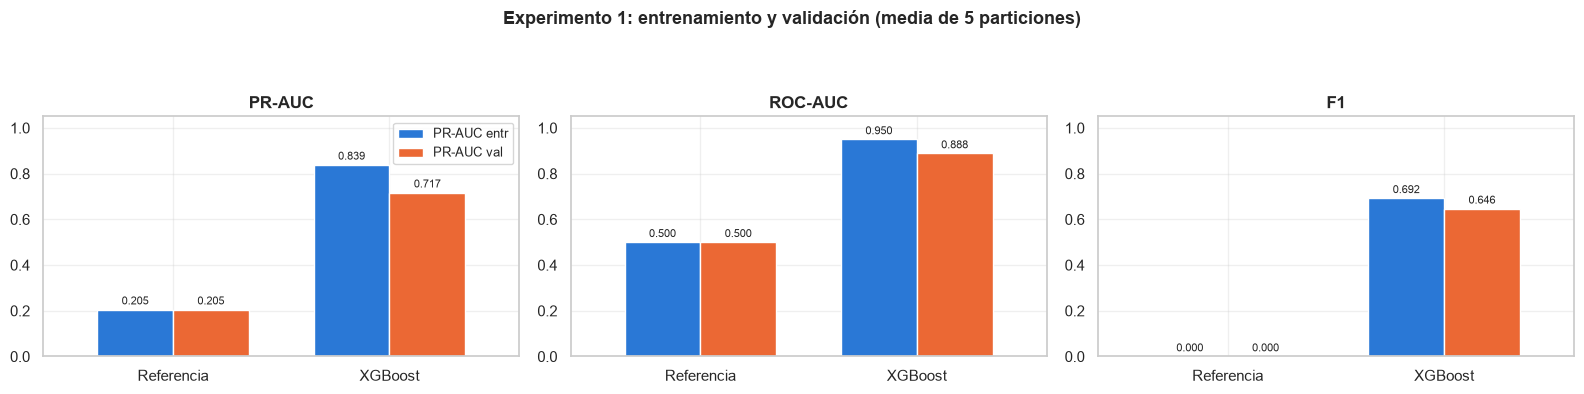

,Partición 1,Partición 2,Partición 3,Partición 4,Partición 5
PR-AUC,0.5679,0.8364,0.6788,0.6602,0.8413
ROC-AUC,0.8013,0.9263,0.8941,0.8802,0.9392
F1,0.5806,0.6316,0.6452,0.6471,0.7273


In [21]:
# ============================================================================
#  9.2 Validación cruzada y sobreajuste
# ============================================================================
tabla_cv1 = pd.DataFrame([fila_cv("Referencia", gs1_ref, list(SCORING_1)),
                          fila_cv("XGBoost", gs1_xgb, list(SCORING_1))]).set_index("Modelo")
display(tabla_cv1[[f"{m} {t}" for m in ["PR-AUC", "ROC-AUC", "F1"] for t in ["entr", "val", "±"]]])

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, m in zip(ax, ["PR-AUC", "ROC-AUC", "F1"]):
    tabla_cv1[[f"{m} entr", f"{m} val"]].plot.bar(ax=a, color=C_SERIE[:2], width=.7, rot=0, legend=(m == "PR-AUC"))
    a.set_title(m); a.set_ylim(0, 1.05); a.set_xlabel("")
    for cont in a.containers:
        a.bar_label(cont, fmt="%.3f", fontsize=8, padding=2)
fig.suptitle("Experimento 1: entrenamiento y validación (media de 5 particiones)", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.9]); plt.show()

r, i = gs1_xgb.cv_results_, gs1_xgb.best_index_
display(pd.DataFrame({m: [r[f"split{k}_test_{m}"][i] for k in range(N_FOLDS)] for m in ["PR-AUC", "ROC-AUC", "F1"]},
                     index=[f"Partición {k + 1}" for k in range(N_FOLDS)]).T)

La regla de un error estándar eligió profundidad 2, `learning_rate` 0.05, `min_child_weight` 5 y `reg_lambda`
10, la combinación más simple con PR-AUC de validación a menos de un error estándar (0.050) de la mejor: 0.717
frente a 0.737. La combinación con el puntaje más alto llegaba a PR-AUC 1.000 en entrenamiento.

El modelo elegido obtiene PR-AUC 0.717 ± 0.106 y ROC-AUC 0.888 en validación, frente a 0.205 y 0.500 de la
referencia. La diferencia entre entrenamiento y validación es de 0.12 en PR-AUC (0.839 y 0.717) y de 0.06 en
ROC-AUC. Entre particiones, el PR-AUC varía de 0.57 a 0.84: con unos 12 superventas por partición de
validación, pocos casos cambian bastante la métrica.

### 9.3 Umbral de decisión

El umbral de 0.5 no tiene una justificación particular, y `scale_pos_weight` desplaza las probabilidades hacia
la clase positiva. El umbral se elige con predicciones de validación cruzada sobre el conjunto de entrenamiento
(`cross_val_predict`: cada libro es predicho por un modelo ajustado sin él), maximizando F1. El panel derecho
muestra la precisión que se obtiene al priorizar una fracción del catálogo ordenado por probabilidad.

Umbral elegido: 0.547 (precisión 0.519, sensibilidad 0.871, F1 0.651)
Priorizando el 10% del catálogo: precisión 0.77, sensibilidad 0.37
Priorizando el 20% del catálogo: precisión 0.60, sensibilidad 0.58


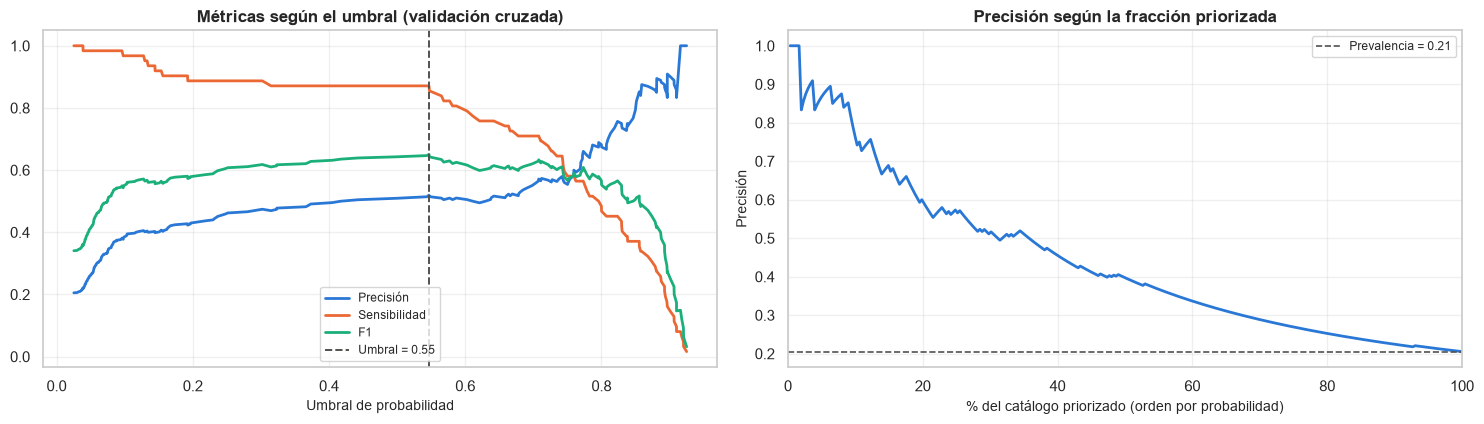

In [22]:
# ============================================================================
#  9.3 Umbral con predicciones de validación cruzada
# ============================================================================
from sklearn.metrics import precision_recall_curve

modelo_1 = gs1_xgb.best_estimator_
proba_vc_1 = cross_val_predict(modelo_1, X_train, y1_tr, cv=CV_CLF, method="predict_proba")[:, 1]

prec, rec, umbrales = precision_recall_curve(y1_tr, proba_vc_1)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
UMBRAL_1 = float(umbrales[np.argmax(f1s)])
print(f"Umbral elegido: {UMBRAL_1:.3f} (precisión {prec[np.argmax(f1s)]:.3f}, "
      f"sensibilidad {rec[np.argmax(f1s)]:.3f}, F1 {f1s.max():.3f})")

orden_vc = np.argsort(-proba_vc_1)
posicion = np.arange(1, len(orden_vc) + 1)
precision_top = np.cumsum(y1_tr.values[orden_vc]) / posicion
sensibilidad_top = np.cumsum(y1_tr.values[orden_vc]) / y1_tr.sum()
for frac in [0.10, 0.20]:
    k = int(round(frac * len(posicion)))
    print(f"Priorizando el {frac:.0%} del catálogo: precisión {precision_top[k - 1]:.2f}, "
          f"sensibilidad {sensibilidad_top[k - 1]:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
ax[0].plot(umbrales, prec[:-1], lw=2, color=C_SERIE[0], label="Precisión")
ax[0].plot(umbrales, rec[:-1], lw=2, color=C_SERIE[1], label="Sensibilidad")
ax[0].plot(umbrales, f1s, lw=2, color=C_SERIE[2], label="F1")
ax[0].axvline(UMBRAL_1, color=C_REF, ls="--", lw=1.4, label=f"Umbral = {UMBRAL_1:.2f}")
ax[0].set_xlabel("Umbral de probabilidad"); ax[0].set_title("Métricas según el umbral (validación cruzada)")
ax[0].legend(fontsize=8.5)
ax[1].plot(posicion / len(posicion) * 100, precision_top, lw=2, color=C_SERIE[0])
ax[1].axhline(y1_tr.mean(), color=C_REF, ls="--", lw=1.2, label=f"Prevalencia = {y1_tr.mean():.2f}")
ax[1].set_xlabel("% del catálogo priorizado (orden por probabilidad)")
ax[1].set_ylabel("Precisión"); ax[1].set_xlim(0, 100)
ax[1].set_title("Precisión según la fracción priorizada"); ax[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

### 9.4 Evaluación en el conjunto de prueba

El modelo y el umbral se fijaron con el conjunto de entrenamiento; esta es la única evaluación sobre prueba.

,Validación cruzada,Prueba
PR-AUC,0.7169,0.7213
ROC-AUC,0.8882,0.9161


Prevalencia en prueba: 0.200

Métricas con umbral 0.547 (prueba):


,Prueba
Precisión,0.5854
Sensibilidad,0.9231
F1,0.7164
Exactitud,0.8538


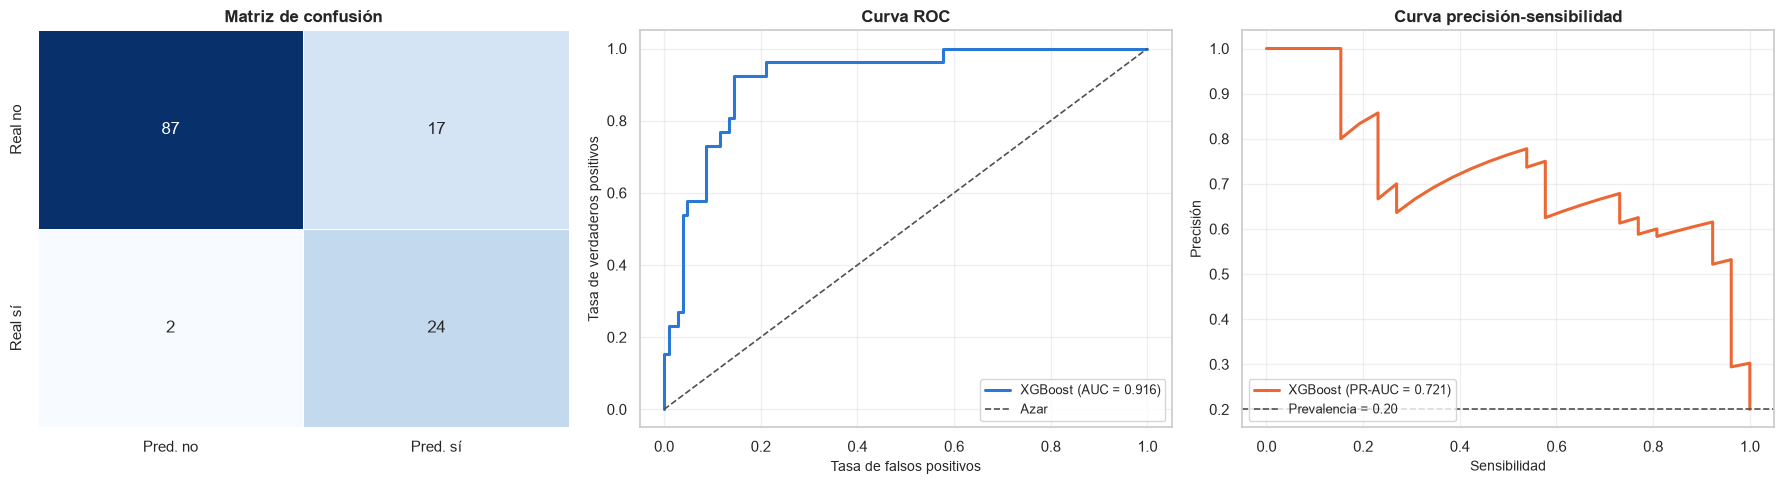

In [23]:
# ============================================================================
#  9.4 Evaluación en el conjunto de prueba
# ============================================================================
from sklearn.metrics import (confusion_matrix, roc_auc_score, average_precision_score, f1_score, roc_curve,
                             accuracy_score, precision_score, recall_score, balanced_accuracy_score)

proba_te_1 = modelo_1.predict_proba(X_test)[:, 1]
pred_te_1  = (proba_te_1 >= UMBRAL_1).astype(int)

display(pd.DataFrame({
    "Validación cruzada": {m: tabla_cv1.loc["XGBoost", f"{m} val"] for m in ["PR-AUC", "ROC-AUC"]},
    "Prueba": {"PR-AUC": average_precision_score(y1_te, proba_te_1), "ROC-AUC": roc_auc_score(y1_te, proba_te_1)},
}))
print(f"Prevalencia en prueba: {y1_te.mean():.3f}")
print(f"\nMétricas con umbral {UMBRAL_1:.3f} (prueba):")
display(pd.Series({"Precisión": precision_score(y1_te, pred_te_1), "Sensibilidad": recall_score(y1_te, pred_te_1),
                   "F1": f1_score(y1_te, pred_te_1), "Exactitud": accuracy_score(y1_te, pred_te_1)}).to_frame("Prueba"))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.heatmap(confusion_matrix(y1_te, pred_te_1), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            linewidths=.5, xticklabels=["Pred. no", "Pred. sí"], yticklabels=["Real no", "Real sí"])
ax[0].set_title("Matriz de confusión")
fpr, tpr, _ = roc_curve(y1_te, proba_te_1)
ax[1].plot(fpr, tpr, lw=2.2, color=C_SERIE[0], label=f"XGBoost (AUC = {roc_auc_score(y1_te, proba_te_1):.3f})")
ax[1].plot([0, 1], [0, 1], ls="--", lw=1.2, color=C_REF, label="Azar")
ax[1].set_xlabel("Tasa de falsos positivos"); ax[1].set_ylabel("Tasa de verdaderos positivos")
ax[1].set_title("Curva ROC"); ax[1].legend(loc="lower right")
p_te, r_te, _ = precision_recall_curve(y1_te, proba_te_1)
ax[2].plot(r_te, p_te, lw=2.2, color=C_SERIE[1], label=f"XGBoost (PR-AUC = {average_precision_score(y1_te, proba_te_1):.3f})")
ax[2].axhline(y1_te.mean(), ls="--", lw=1.2, color=C_REF, label=f"Prevalencia = {y1_te.mean():.2f}")
ax[2].set_xlabel("Sensibilidad"); ax[2].set_ylabel("Precisión"); ax[2].set_title("Curva precisión-sensibilidad")
ax[2].legend(loc="lower left")
plt.tight_layout(); plt.show()

En el conjunto de prueba, el PR-AUC es 0.721 y el ROC-AUC 0.916, valores consistentes con la validación cruzada
(0.717 y 0.888). Con el umbral de 0.547 se detectan 24 de los 26 superventas (sensibilidad 0.92), con precisión
0.59 y 17 falsos positivos. Si un falso positivo fuera más costoso que un falso negativo, convendría subir el
umbral (curva de 9.3).

### 9.5 Interpretación con SHAP

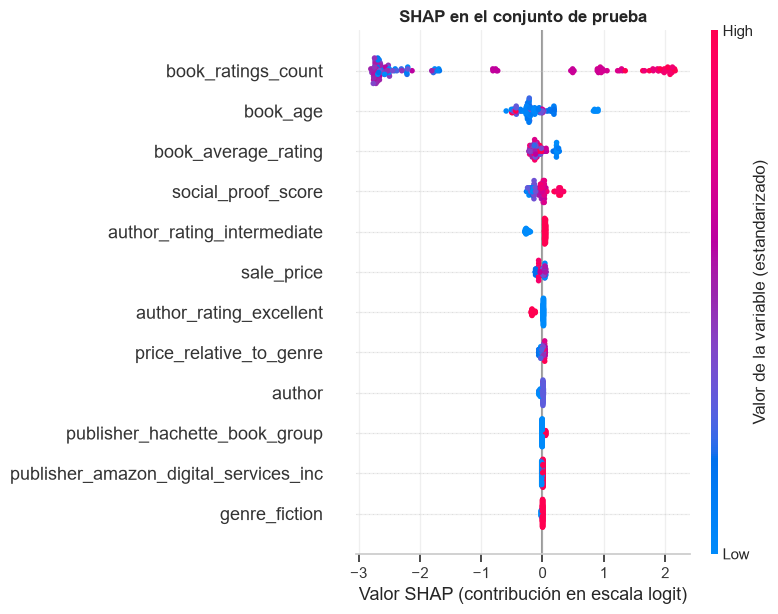

,|SHAP| medio
book_ratings_count,2.1126
book_age,0.2594
book_average_rating,0.1207
social_proof_score,0.1067
author_rating_intermediate,0.0935
sale_price,0.0432
author_rating_excellent,0.0401
price_relative_to_genre,0.0281
author,0.0123
publisher_hachette_book_group,0.0093


Proporción de superventas por quintil de book_ratings_count (entrenamiento):


,proporcion,libros
quintil,,
"(37378.999, 82930.0]",0.0000,61
"(82930.0, 109850.0]",0.0333,60
"(109850.0, 126457.2]",0.0167,60
"(126457.2, 143544.8]",0.3333,60
"(143544.8, 206792.0]",0.6393,61


In [24]:
# ============================================================================
#  9.5 Interpretación con SHAP
# ============================================================================
import shap

nombres_1 = modelo_1.named_steps["prep"].get_feature_names_out()
Xt_te_1 = pd.DataFrame(modelo_1[:-1].transform(X_test), columns=nombres_1, index=X_test.index)
shap_1 = shap.TreeExplainer(modelo_1.named_steps["modelo"]).shap_values(Xt_te_1)

shap.summary_plot(shap_1, Xt_te_1, plot_type="dot", show=False, max_display=12)
fig = plt.gcf()
fig.axes[0].set_xlabel("Valor SHAP (contribución en escala logit)")
fig.axes[-1].set_ylabel("Valor de la variable (estandarizado)")
plt.title("SHAP en el conjunto de prueba", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

imp_shap_1 = pd.Series(np.abs(shap_1).mean(axis=0), index=nombres_1).sort_values(ascending=False)
display(imp_shap_1.head(10).rename("|SHAP| medio").to_frame())

print("Proporción de superventas por quintil de book_ratings_count (entrenamiento):")
display(pd.DataFrame({"quintil": pd.qcut(X_train["book_ratings_count"], 5), "y": y1_tr})
        .groupby("quintil", observed=True)["y"].agg(proporcion="mean", libros="size"))

`book_ratings_count` concentra la mayor parte de la contribución (|SHAP| medio 2.11, frente a 0.26 de
`book_age`, la siguiente): los valores altos aumentan la probabilidad y los bajos la reducen. En
entrenamiento, la proporción de superventas es de 0 a 3 % en los tres quintiles inferiores de esa variable,
33 % en el cuarto y 64 % en el quinto. Precio, editorial, género y autor tienen contribuciones pequeñas.

Como la cantidad de calificaciones depende de la cantidad de lectores, funciona como un indicador indirecto de
las ventas. Por eso el modelo es útil cuando esa información existe, es decir, para títulos ya publicados, y
no antes del lanzamiento (9.7).

### 9.6 Análisis de errores

Falsos negativos:


,book_name,author,genre,publisher,sale_price,book_average_rating,book_ratings_count,units_sold,probabilidad,real,predicho,tipo
40,"Men Are from Mars, Women Are from Venus Book of Days: 365 Inspirations to En...",John Gray,fiction,amazon_digital_services_inc,1.9900,3.5200,113915,1861,0.0512,1,0,FN
83,Plain Truth,Jodi Picoult,fiction,amazon_digital_services_inc,0.9900,3.9700,128406,1200,0.3036,1,0,FN


Falsos positivos:


,book_name,author,genre,publisher,sale_price,book_average_rating,book_ratings_count,units_sold,probabilidad,real,predicho,tipo
93,The Polar Express,Chris Van Allsburg,non_fiction,amazon_digital_services_inc,0.9900,4.2900,168001,1046,0.9110,0,1,FP
144,Mad About Madeline,Ludwig Bemelmans,fiction,amazon_digital_services_inc,0.9900,4.2200,156726,720,0.9059,0,1,FP
107,The Last Battle,C.S. Lewis,fiction,amazon_digital_services_inc,6.5000,4.0200,158701,920,0.9029,0,1,FP
146,Little House In The Big Woods,"Laura Ingalls Wilder, Garth Williams",fiction,amazon_digital_services_inc,0.9900,4.1600,165127,705,0.8969,0,1,FP
91,All Together Dead,Charlaine Harris,fiction,random_house_llc,6.4900,4.0500,162689,1076,0.8711,0,1,FP
109,Chosen: A House of Night Novel,"P.C. Cast, Kristin Cast",fiction,amazon_digital_services_inc,8.4800,3.9000,180961,915,0.8568,0,1,FP
94,The True Story of the Three Little Pigs,"Jon Scieszka, Lane Smith",fiction,amazon_digital_services_inc,0.9900,4.2900,141945,1030,0.8536,0,1,FP
95,Patriot Games,Tom Clancy,fiction,amazon_digital_services_inc,5.9900,4.1100,141674,1015,0.8483,0,1,FP
132,Along for the Ride,Sarah Dessen,fiction,penguin_group_usa_llc,11.9900,4.0800,151721,785,0.8397,0,1,FP
210,Sabriel,Garth Nix,fiction,random_house_llc,19.9800,4.1700,137047,441,0.7442,0,1,FP


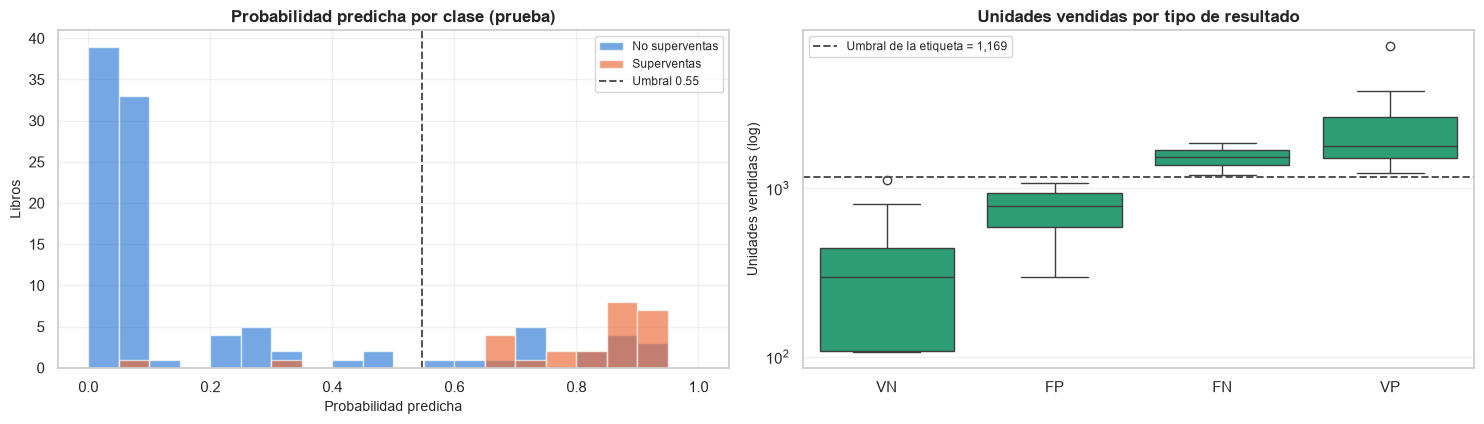

,count,min,50%,max
tipo,,,,
VN,87.0000,106.00,298.00,"1,123.00"
FP,17.0000,296.00,785.00,"1,076.00"
FN,2.0000,"1,200.00","1,530.50","1,861.00"
VP,24.0000,"1,230.00","1,792.00","7,000.00"


In [25]:
# ============================================================================
#  9.6 Análisis de errores
# ============================================================================
errores_1 = (df_modelo.loc[X_test.index, ["book_name", "author", "genre", "publisher", "sale_price",
                                          "book_average_rating", "book_ratings_count", "units_sold"]]
             .assign(probabilidad=proba_te_1, real=y1_te.values, predicho=pred_te_1))
errores_1["tipo"] = np.select(
    [(errores_1.real == 1) & (errores_1.predicho == 1), (errores_1.real == 0) & (errores_1.predicho == 0),
     (errores_1.real == 0) & (errores_1.predicho == 1)], ["VP", "VN", "FP"], default="FN")

print("Falsos negativos:")
display(errores_1[errores_1.tipo == "FN"].sort_values("probabilidad"))
print("Falsos positivos:")
display(errores_1[errores_1.tipo == "FP"].sort_values("probabilidad", ascending=False))

orden_tipos = ["VN", "FP", "FN", "VP"]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
for clase, color, etiqueta in [(0, C_SERIE[0], "No superventas"), (1, C_SERIE[1], "Superventas")]:
    ax[0].hist(proba_te_1[y1_te.values == clase], bins=20, range=(0, 1), alpha=.65, color=color, label=etiqueta)
ax[0].axvline(UMBRAL_1, color=C_REF, ls="--", lw=1.4, label=f"Umbral {UMBRAL_1:.2f}")
ax[0].set_xlabel("Probabilidad predicha"); ax[0].set_ylabel("Libros")
ax[0].set_title("Probabilidad predicha por clase (prueba)"); ax[0].legend(fontsize=8.5)
sns.boxplot(data=errores_1, x="tipo", y="units_sold", order=orden_tipos, ax=ax[1], color=C_SERIE[2])
ax[1].axhline(UMBRAL_BESTSELLER, color=C_REF, ls="--", lw=1.4, label=f"Umbral de la etiqueta = {UMBRAL_BESTSELLER:,.0f}")
ax[1].set_yscale("log"); ax[1].set_xlabel(""); ax[1].set_ylabel("Unidades vendidas (log)")
ax[1].set_title("Unidades vendidas por tipo de resultado"); ax[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

display(errores_1.groupby("tipo")["units_sold"].describe()[["count", "min", "50%", "max"]].reindex(orden_tipos))

Los errores se concentran cerca del umbral de la etiqueta (1.169 unidades). Los 17 falsos positivos vendieron
entre 296 y 1.076 unidades (mediana 785) y los 2 falsos negativos, 1.200 y 1.861.

Los falsos positivos tienen entre 132.000 y 181.000 calificaciones (cuarto y quinto quintil). Varios son libros
infantiles o clásicos que se venden a USD 0.99 en Amazon, como *The Polar Express*, *Mad About Madeline*, *Little
House in the Big Woods* y *The True Story of the Three Little Pigs*; es posible que hayan acumulado calificaciones
durante muchos años con ventas moderadas. Una variable de calificaciones por año desde la publicación permitiría
comprobarlo. Los dos falsos negativos son títulos de Amazon a USD 0.99 y 1.99 con 114.000 y 128.000
calificaciones.

### 9.7 Sensibilidad al momento de la decisión

Validación cruzada sin las variables de calificaciones (`book_average_rating`, `book_ratings_count`,
`social_proof_score`), que no existirían antes del lanzamiento. Se reutilizan los hiperparámetros de 9.1,
elegidos con esas variables; una búsqueda propia podría mejorar levemente el resultado.

In [26]:
# ============================================================================
#  9.7 Validación cruzada sin calificaciones
# ============================================================================
pipe_lanz = construir_pipeline(clone(xgb_clf), cols_num=["sale_price", "book_age", "price_relative_to_genre"])
pipe_lanz.set_params(**gs1_xgb.best_params_)
res_lanz = cross_validate(pipe_lanz, X_train, y1_tr, cv=CV_CLF, scoring=SCORING_1, n_jobs=-1)

display(pd.DataFrame({
    "Con calificaciones": {m: tabla_cv1.loc["XGBoost", f"{m} val"] for m in ["PR-AUC", "ROC-AUC", "F1"]},
    "Sin calificaciones": {m: res_lanz[f"test_{m}"].mean() for m in ["PR-AUC", "ROC-AUC", "F1"]},
    "Referencia"        : {m: tabla_cv1.loc["Referencia", f"{m} val"] for m in ["PR-AUC", "ROC-AUC", "F1"]},
}))

,Con calificaciones,Sin calificaciones,Referencia
PR-AUC,0.7169,0.2675,0.2052
ROC-AUC,0.8882,0.6024,0.5000
F1,0.6463,0.3342,0.0000


Sin las calificaciones, el PR-AUC baja de 0.717 a 0.268 y el ROC-AUC de 0.888 a 0.602, cerca de la referencia
(0.205 y 0.500). En este dataset, precio, editorial, género, autor y antigüedad anticipan poco las ventas, de
modo que el modelo sirve para títulos con calificaciones acumuladas y no para decisiones previas al
lanzamiento.

---
## 10. Experimento 2: regresión de unidades vendidas y elasticidad de precio

### 10.1 Objetivo en escala logarítmica

En el bloque A, `units_sold` tiene asimetría 2.83 (4.6), por lo que se modela z = log(1 + `units_sold`). Si el
error es multiplicativo (y = μ·ε), en escala logarítmica es aditivo, que es el supuesto bajo el cual minimizar
el error cuadrático resulta adecuado. Además, un error en escala logarítmica equivale aproximadamente a un error
relativo. Se usa `log1p` por convención: con un mínimo de 106 unidades, `log` daría prácticamente lo mismo.

Al volver a unidades con `expm1`, la predicción se aproxima a la mediana condicional y no a la media
(desigualdad de Jensen). Las unidades predichas en 10.4, 10.7 y 12 deben leerse como valores medianos.

### 10.2 Candidatos

| | Ridge | XGBoost | LightGBM |
|---|---|---|---|
| Forma | lineal | árboles que crecen por niveles | árboles que crecen por hojas |
| Interacciones | no | sí | sí |
| Control de complejidad | `alpha` | `max_depth`, `min_child_weight` | `num_leaves`, `min_child_samples` |

In [27]:
# ============================================================================
#  10.2 Búsqueda de hiperparámetros
# ============================================================================
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

SCORING_2 = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}

busquedas_2 = {
    "Referencia": buscar("Referencia", construir_pipeline(DummyRegressor(strategy="mean")),
                         {"modelo__strategy": ["mean"]}, X_train, y2_tr, CV_REG, SCORING_2, "RMSE"),
    "Ridge": buscar("Ridge", construir_pipeline(Ridge()), {"modelo__alpha": [0.1, 1, 10, 100]},
                    X_train, y2_tr, CV_REG, SCORING_2, "RMSE", complejidad_ridge),
    "XGBoost": buscar("XGBoost", construir_pipeline(XGBRegressor(
                          objective="reg:squarederror", subsample=0.8, colsample_bytree=0.8,
                          tree_method="hist", random_state=RANDOM_STATE, n_jobs=1)),
                      {"modelo__n_estimators": [200, 400], "modelo__max_depth": [3, 5, 8],
                       "modelo__learning_rate": [0.05, 0.1], "modelo__min_child_weight": [1, 3]},
                      X_train, y2_tr, CV_REG, SCORING_2, "RMSE", complejidad_boosting),
    "LightGBM": buscar("LightGBM", construir_pipeline(LGBMRegressor(
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                           random_state=RANDOM_STATE, n_jobs=1, verbose=-1)),
                       {"modelo__n_estimators": [200, 400], "modelo__num_leaves": [15, 31],
                        "modelo__learning_rate": [0.05, 0.1], "modelo__min_child_samples": [10, 20]},
                       X_train, y2_tr, CV_REG, SCORING_2, "RMSE", complejidad_boosting),
}
for nombre in ["Ridge", "XGBoost", "LightGBM"]:
    print(f"{nombre}: {busquedas_2[nombre].best_params_}")

[Referencia] 1 combinaciones | mejor RMSE val = 1.0089 | elegida: val = 1.0089, entr = 1.0102


[Ridge] 4 combinaciones | mejor RMSE val = 0.5502 | elegida: val = 0.5502, entr = 0.5264


[XGBoost] 24 combinaciones | mejor RMSE val = 0.5581 | elegida: val = 0.5615, entr = 0.3099


[LightGBM] 16 combinaciones | mejor RMSE val = 0.5871 | elegida: val = 0.5909, entr = 0.3713
Ridge: {'modelo__alpha': 10}
XGBoost: {'modelo__learning_rate': 0.05, 'modelo__max_depth': 3, 'modelo__min_child_weight': 3, 'modelo__n_estimators': 200}
LightGBM: {'modelo__learning_rate': 0.05, 'modelo__min_child_samples': 20, 'modelo__n_estimators': 200, 'modelo__num_leaves': 15}


### 10.3 Comparación por validación cruzada y elección del modelo

Escala log1p; en RMSE y MAE, menor es mejor.


,RMSE entr,RMSE val,RMSE ±,MAE entr,MAE val,MAE ±,R2 entr,R2 val,R2 ±
Modelo,,,,,,,,,
Referencia,1.0102,1.0089,0.0715,0.8137,0.8147,0.0778,0.0000,-0.0033,0.0033
Ridge,0.5264,0.5502,0.0561,0.3944,0.4114,0.0415,0.7282,0.7019,0.0276
XGBoost,0.3099,0.5615,0.0463,0.2322,0.4142,0.0416,0.9055,0.6885,0.0260
LightGBM,0.3713,0.5909,0.0636,0.2678,0.4307,0.0533,0.8649,0.6571,0.0264


Modelo elegido: Ridge


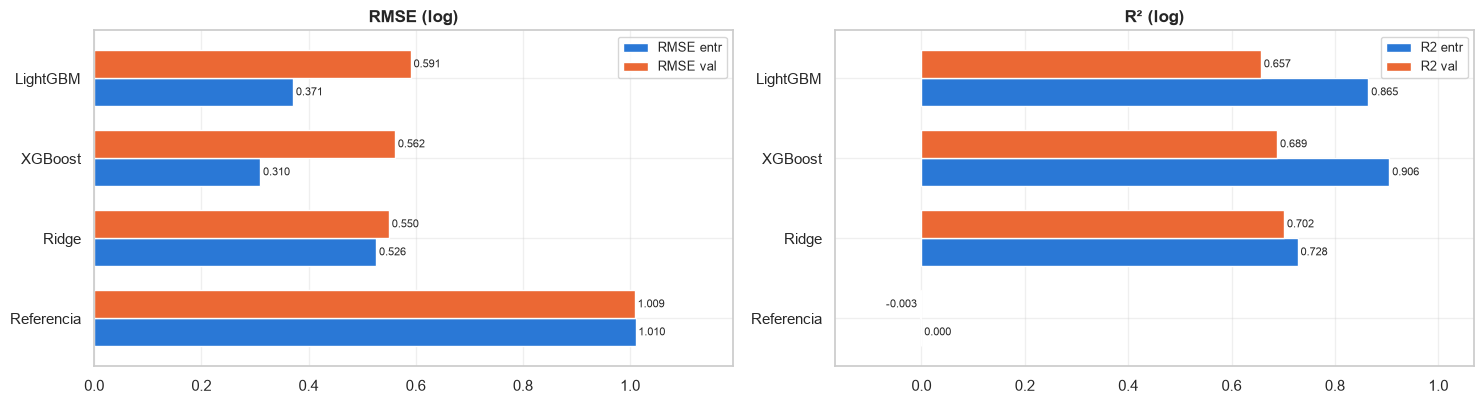

In [28]:
# ============================================================================
#  10.3 Comparación por validación cruzada y elección del modelo
# ============================================================================
tabla_cv2 = pd.DataFrame([fila_cv(n, gs, list(SCORING_2), negativas=("RMSE", "MAE"))
                          for n, gs in busquedas_2.items()]).set_index("Modelo")
print("Escala log1p; en RMSE y MAE, menor es mejor.")
display(tabla_cv2)

GANADOR_2 = elegir_modelo(tabla_cv2, "RMSE", ["Ridge", "XGBoost", "LightGBM"], mayor_es_mejor=False)
modelo_2 = busquedas_2[GANADOR_2].best_estimator_
print(f"Modelo elegido: {GANADOR_2}")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
tabla_cv2[["RMSE entr", "RMSE val"]].plot.barh(ax=ax[0], color=C_SERIE[:2], width=.7)
ax[0].set_title("RMSE (log)"); ax[0].set_ylabel("")
tabla_cv2[["R2 entr", "R2 val"]].plot.barh(ax=ax[1], color=C_SERIE[:2], width=.7)
ax[1].set_title("R² (log)"); ax[1].set_ylabel("")
for a in ax:
    for cont in a.containers:
        a.bar_label(cont, fmt="%.3f", fontsize=8, padding=2)
    a.margins(x=.18)
plt.tight_layout(); plt.show()

Los tres modelos reducen el RMSE de validación de 1.009 (referencia) a valores entre 0.55 y 0.59, con R² entre
0.66 y 0.70. Ridge tiene el menor RMSE (0.550); XGBoost (0.562) queda dentro de un error estándar (0.025) y
LightGBM (0.591) fuera, así que se elige Ridge, el más simple de los que cumplen la regla.

El RMSE de entrenamiento y de validación es 0.31 y 0.56 en XGBoost, 0.37 y 0.59 en LightGBM, y 0.53 y 0.55 en
Ridge. Los modelos de boosting se ajustan mucho más al conjunto de entrenamiento sin mejorar en validación.

### 10.4 Evaluación en el conjunto de prueba

In [29]:
# ============================================================================
#  10.4 Evaluación en el conjunto de prueba
# ============================================================================
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def metricas_regresion(y_log, pred_log):
    real_u, pred_u = np.expm1(y_log), np.expm1(pred_log)
    return {"RMSE (log)": np.sqrt(mean_squared_error(y_log, pred_log)),
            "MAE (log)" : mean_absolute_error(y_log, pred_log),
            "R² (log)"  : r2_score(y_log, pred_log),
            "RMSE (unid.)": np.sqrt(mean_squared_error(real_u, pred_u)),
            "MAE (unid.)" : mean_absolute_error(real_u, pred_u),
            "Error absoluto mediano (unid.)": float(np.median(np.abs(real_u - pred_u))),
            "R² (unid.)"  : r2_score(real_u, pred_u)}

pred_te_2 = modelo_2.predict(X_test)
tabla_test_2 = pd.DataFrame({GANADOR_2: metricas_regresion(y2_te, pred_te_2),
                             "Referencia (media de entrenamiento)": metricas_regresion(y2_te, np.full(len(y2_te), y2_tr.mean()))})
display(tabla_test_2)

mae_log = tabla_test_2.loc["MAE (log)", GANADOR_2]
print(f"MAE (log) = {mae_log:.3f}: factor típico x{np.exp(mae_log):.2f} "
      f"(entre {np.exp(-mae_log) - 1:+.0%} y {np.exp(mae_log) - 1:+.0%} respecto del valor real)")

,Ridge,Referencia (media de entrenamiento)
RMSE (log),0.4516,1.0210
MAE (log),0.3450,0.8334
R² (log),0.8042,-0.0009
RMSE (unid.),703.13,994.48
MAE (unid.),315.00,545.67
Error absoluto mediano (unid.),86.0599,325.31
R² (unid.),0.4491,-0.1019


MAE (log) = 0.345: factor típico x1.41 (entre -29% y +41% respecto del valor real)


### 10.5 Residuos y análisis de errores

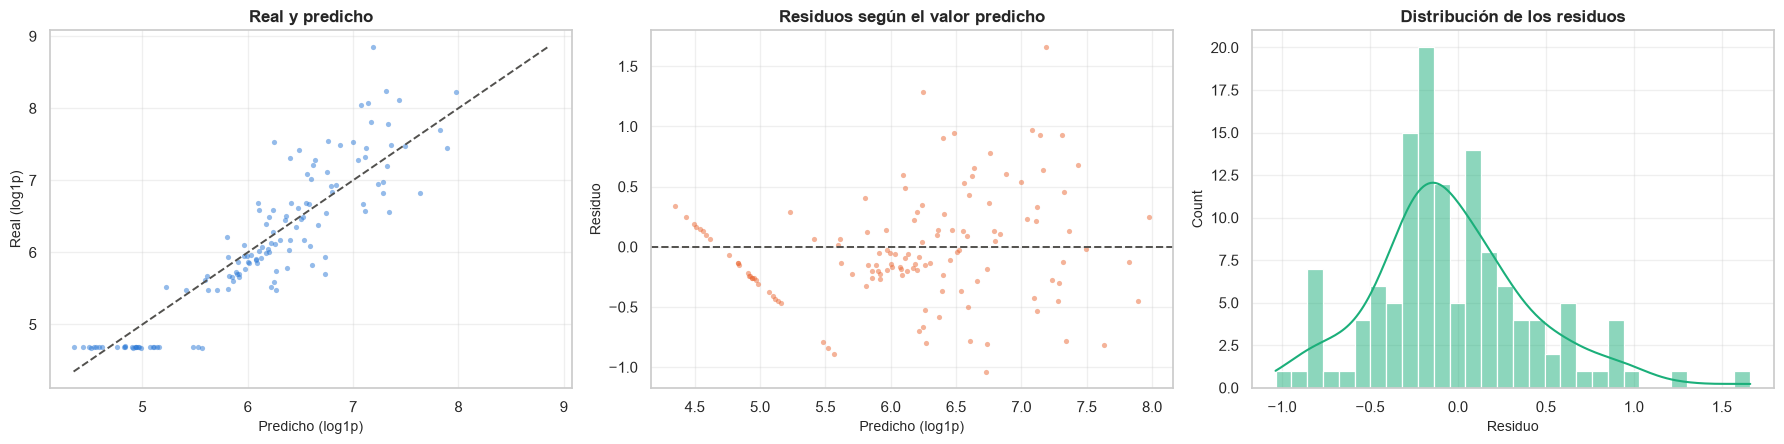

Residuos: media -0.0274 | desvío 0.4508

Valores más bajos de units_sold en el bloque A (libros por valor):
{106: 23, 107: 28, 108: 31, 109: 4, 233: 1, 234: 1}
Libros con 106 a 109 unidades: 86 (20% del bloque A); siguiente valor: 233

Error por cuartil de ventas reales (sesgo > 0: subestimación):


,libros,sesgo_log,mae_log,real_mediano,predicho_mediano
cuartil,,,,,
Q1,33,-0.2203,0.3073,108.00,139.11
Q2,32,-0.2497,0.2807,332.00,406.08
Q3,32,-0.0582,0.2704,635.00,599.79
Q4,33,0.4111,0.5174,"1,707.00","1,228.29"


Ocho libros con mayor error (escala log):


,book_name,author,publisher,sale_price,units_sold,predicho,residuo_log
0,Beowulf,"Unknown, Seamus Heaney",harpercollins_publishers,4.8800,7000,"1,327.00",1.6625
40,"Men Are from Mars, Women Are from Venus Book of Days: 365 Inspirations to En...",John Gray,amazon_digital_services_inc,1.9900,1861,515.00,1.2831
290,The DUFF: Designated Ugly Fat Friend,Kody Keplinger,amazon_digital_services_inc,3.9900,296,836.00,-1.0366
18,Corduroy,Don Freeman,simon_and_schuster_digital_sales_inc,1.9900,3133,"1,186.00",0.9705
52,デスノート #1 (Desu Nōto) Taikutsu (退屈),"Tsugumi Ohba, Takeshi Obata",amazon_digital_services_inc,3.9900,1676,653.00,0.9424
7,Midnight in the Garden of Good and Evil,John Berendt,hachette_book_group,6.8900,3800,"1,501.00",0.9286
17,Pretty Little Liars,Sara Shepard,amazon_digital_services_inc,4.9900,3200,"1,268.00",0.9248
64,Don Quijote de La Mancha,"Miguel de Cervantes Saavedra, Roberto González Echevarría, John Rutherford",hachette_book_group,8.9900,1492,603.00,0.9057


In [30]:
# ============================================================================
#  10.5 Residuos y análisis de errores
# ============================================================================
resid_2 = y2_te.values - pred_te_2

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
ax[0].scatter(pred_te_2, y2_te, s=14, alpha=.5, color=C_SERIE[0], linewidths=0)
lims = [min(pred_te_2.min(), y2_te.min()), max(pred_te_2.max(), y2_te.max())]
ax[0].plot(lims, lims, ls="--", lw=1.4, color=C_REF)
ax[0].set_xlabel("Predicho (log1p)"); ax[0].set_ylabel("Real (log1p)"); ax[0].set_title("Real y predicho")
ax[1].scatter(pred_te_2, resid_2, s=14, alpha=.5, color=C_SERIE[1], linewidths=0)
ax[1].axhline(0, ls="--", lw=1.4, color=C_REF)
ax[1].set_xlabel("Predicho (log1p)"); ax[1].set_ylabel("Residuo"); ax[1].set_title("Residuos según el valor predicho")
sns.histplot(resid_2, bins=30, kde=True, ax=ax[2], color=C_SERIE[2])
ax[2].set_title("Distribución de los residuos"); ax[2].set_xlabel("Residuo")
plt.tight_layout(); plt.show()
print(f"Residuos: media {resid_2.mean():+.4f} | desvío {resid_2.std():.4f}")

print("\nValores más bajos de units_sold en el bloque A (libros por valor):")
print(df_modelo["units_sold"].value_counts().sort_index().head(6).to_dict())
en_piso = df_modelo["units_sold"] <= 109
print(f"Libros con 106 a 109 unidades: {int(en_piso.sum())} ({en_piso.mean():.0%} del bloque A); "
      f"siguiente valor: {df_modelo.loc[~en_piso, 'units_sold'].min()}")

seg = pd.qcut(np.expm1(y2_te), 4, labels=["Q1", "Q2", "Q3", "Q4"])
print("\nError por cuartil de ventas reales (sesgo > 0: subestimación):")
display(pd.DataFrame({"cuartil": seg, "residuo": resid_2, "real": np.expm1(y2_te), "predicho": np.expm1(pred_te_2)})
        .groupby("cuartil", observed=True)
        .agg(libros=("real", "size"), sesgo_log=("residuo", "mean"), mae_log=("residuo", lambda s: s.abs().mean()),
             real_mediano=("real", "median"), predicho_mediano=("predicho", "median")))

print("Ocho libros con mayor error (escala log):")
display(df_modelo.loc[X_test.index, ["book_name", "author", "publisher", "sale_price", "units_sold"]]
        .assign(predicho=np.expm1(pred_te_2).round(0), residuo_log=resid_2)
        .sort_values("residuo_log", key=abs, ascending=False).head(8))

En el conjunto de prueba, el RMSE es 0.452 y el R² 0.80 en escala logarítmica, mejores que en validación
cruzada (0.550 ± 0.056). La partición de prueba resultó favorable; la estimación de validación cruzada es la
referencia más estable del desempeño esperado.

El MAE en escala logarítmica es 0.345, es decir, la predicción difiere del valor real en un factor típico de
1.41 (entre −29 % y +41 %). En unidades, el error absoluto mediano es 86 y el MAE 315. El R² en unidades es menor
(0.45) porque los errores absolutos grandes se concentran en los libros más vendidos.

El modelo sobreestima los dos cuartiles de menores ventas (sesgo de −0.22 y −0.25 en escala logarítmica) y
subestima el superior (+0.41; mediana real 1.707 y predicha 1.228). Los mayores errores son libros que vendieron
bastante más de lo que predice su cantidad de calificaciones, como *Beowulf* (7.000 unidades reales y 1.327
predichas).

La franja diagonal a la izquierda del gráfico de residuos corresponde a libros con 106 a 109 unidades. Hay 86
libros (20 % del bloque A) con uno de esos cuatro valores y el siguiente valor observado es 233, lo que sugiere un
piso de registro en la fuente. Como el valor real es casi constante y la predicción varía, sus residuos quedan
sobre una recta. Fuera de esa franja, los residuos están centrados (media −0.03) y no muestran forma de embudo.

### 10.6 Importancia de las variables por permutación

,aumento_RMSE,desvío
book_ratings_count,0.7909,0.0590
author_rating,0.0564,0.0119
publisher,0.0070,0.0056
genre,0.0062,0.0050
sale_price,0.0055,0.0033
publishing_year,0.0039,0.0068
book_average_rating,0.0001,0.0007
author,0.0000,0.0022


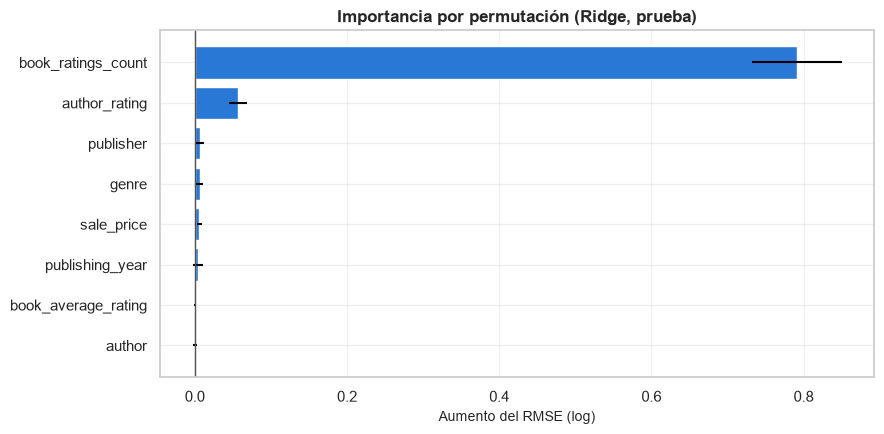

In [31]:
# ============================================================================
#  10.6 Importancia de las variables por permutación
# ============================================================================
from sklearn.inspection import permutation_importance

# Se permutan las columnas de entrada, de modo que la importancia se expresa en las variables originales
pi_2 = permutation_importance(modelo_2, X_test, y2_te, scoring="neg_root_mean_squared_error",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp_2 = pd.DataFrame({"aumento_RMSE": pi_2.importances_mean, "desvío": pi_2.importances_std},
                     index=X_test.columns).sort_values("aumento_RMSE")
display(imp_2[::-1])

plt.figure(figsize=(9, 4.5))
plt.barh(imp_2.index, imp_2["aumento_RMSE"], xerr=imp_2["desvío"], color=C_SERIE[0])
plt.axvline(0, color=C_REF, lw=1)
plt.title(f"Importancia por permutación ({GANADOR_2}, prueba)"); plt.xlabel("Aumento del RMSE (log)")
plt.tight_layout(); plt.show()

Al permutar `book_ratings_count` el RMSE aumenta 0.79 y el modelo queda peor que la referencia. Le sigue
`author_rating` (0.056); editorial, género, precio y año aportan menos de 0.01 cada uno. `author` aporta
prácticamente nada, porque la mayoría de los autores tiene uno o dos libros y la codificación por objetivo los
acerca a la media global. El precio casi no influye en la predicción, lo que anticipa el resultado de la
simulación siguiente.

### 10.7 Simulación de elasticidad de precio

La elasticidad precio de la demanda es $\varepsilon = \partial \ln Q / \partial \ln P$. Con $\varepsilon < -1$
(demanda elástica), bajar el precio aumenta el ingreso; con $-1 < \varepsilon < 0$ (demanda inelástica),
subirlo lo aumenta.

Para tres libros del conjunto de prueba, con ventas cercanas a los percentiles 25, 50 y 95, se varía
`sale_price` manteniendo fijos los demás atributos y se calcula el ingreso $P \cdot \hat Q(P)$. En cada escenario
el pipeline recalcula `price_relative_to_genre` con las medias de entrenamiento. El precio se limita a los
percentiles 2 a 98 de entrenamiento para no extrapolar fuera del rango observado.

Ridge es lineal en $\log(1+Q)$: $\ln \hat Q \approx a + b\,P + c\,P/\bar P_g$, donde $\bar P_g$ es el precio
medio del género, y por lo tanto $\varepsilon \approx (b + c/\bar P_g)\,P$, que crece en valor absoluto con el
precio.

La simulación es observacional, porque en el catálogo el precio no se asignó al azar. Las curvas muestran la
predicción del modelo para un libro con esos atributos y ese precio, no el efecto causal de cambiarlo.

#### 10.7.1 Funciones de simulación

In [32]:
# ============================================================================
#  10.7.1 Funciones de simulación
# ============================================================================
PRECIO_MIN_SIM = float(X_train["sale_price"].quantile(0.02))
PRECIO_MAX_SIM = float(X_train["sale_price"].quantile(0.98))
PRECIOS_SIM    = np.linspace(PRECIO_MIN_SIM, PRECIO_MAX_SIM, 91)
PASO_SIM       = PRECIOS_SIM[1] - PRECIOS_SIM[0]

def simular_precio(fila: pd.Series, modelo, precios=PRECIOS_SIM) -> pd.DataFrame:
    '''Repite un libro variando solo sale_price; el pipeline recalcula las variables derivadas.'''
    escenarios = pd.DataFrame([fila[COLUMNAS_ENTRADA]] * len(precios)).reset_index(drop=True)
    escenarios = escenarios.astype(X_train.dtypes.to_dict())
    escenarios["sale_price"] = precios
    unidades = np.clip(np.expm1(modelo.predict(escenarios)), 0, None)
    sim = pd.DataFrame({"precio": precios, "unidades": unidades, "ingreso": precios * unidades})
    sim["elasticidad"] = np.gradient(np.log(np.clip(sim["unidades"], 1e-9, None)), np.log(sim["precio"]))
    return sim

# Tres libros del conjunto de prueba con ventas cercanas a P25, P50 y P95
df_test = df_modelo.loc[X_test.index]
seleccion = list(dict.fromkeys((df_test["units_sold"] - q).abs().idxmin()
                               for q in df_test["units_sold"].quantile([0.25, 0.50, 0.95])))
etiquetas = ["P25", "P50", "P95"][:len(seleccion)]

print(f"Rango de precios (percentiles 2 a 98 de entrenamiento): USD {PRECIO_MIN_SIM:.2f} a {PRECIO_MAX_SIM:.2f}")
display(df_test.loc[seleccion, ["book_name", "author", "genre", "publisher", "sale_price", "units_sold",
                                "book_average_rating", "book_ratings_count"]].assign(segmento=etiquetas))

Rango de precios (percentiles 2 a 98 de entrenamiento): USD 0.99 a 11.99


,book_name,author,genre,publisher,sale_price,units_sold,book_average_rating,book_ratings_count,segmento
333,Brain on Fire,Susannah Cahalan,fiction,hachette_book_group,10.6500,241,4.0000,92849,P25
226,The Bluest Eye,Toni Morrison,fiction,amazon_digital_services_inc,2.9900,408,3.9900,109944,P50
25,The Virgin Suicides,Jeffrey Eugenides,fiction,penguin_group_usa_llc,10.9100,2466,3.8300,159249,P95


#### 10.7.2 Curvas de demanda, ingreso y elasticidad

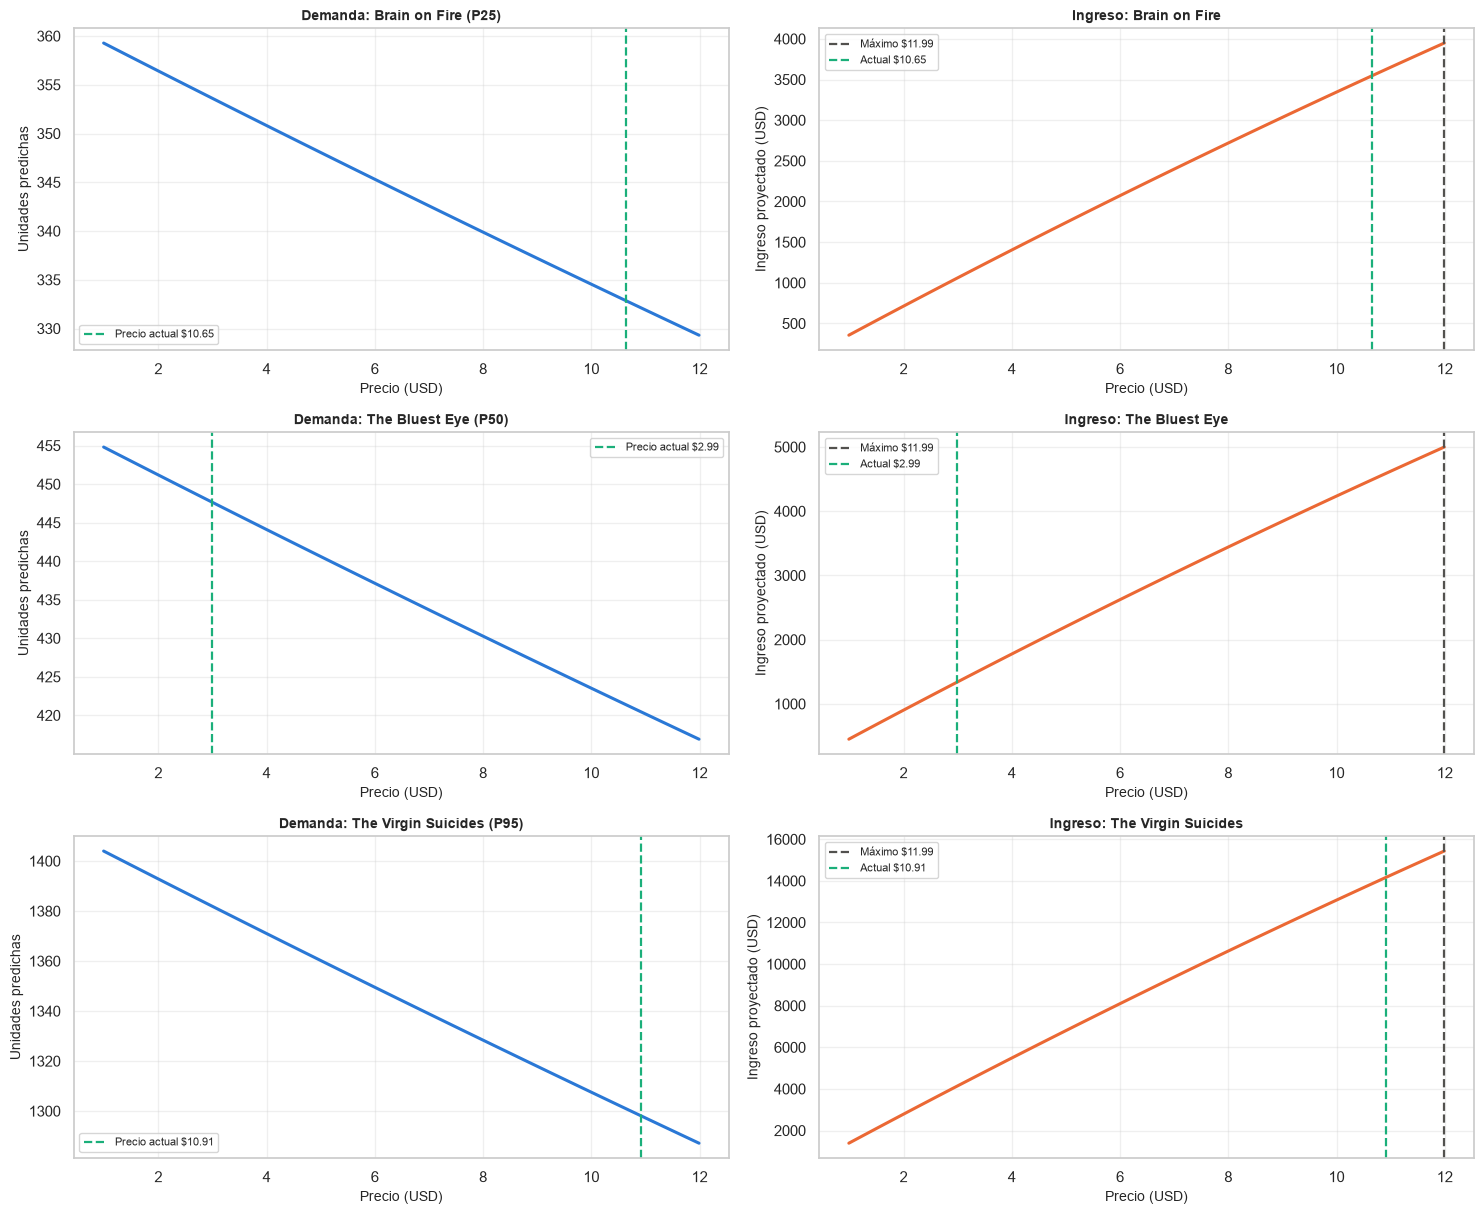

,segmento,precio_actual,precio_ingreso_max,en_borde_superior,elasticidad_en_actual,variacion_unidades_%
libro,,,,,,
Brain on Fire,P25,10.6500,11.9900,True,-0.0843,-8.3401
The Bluest Eye,P50,2.9900,11.9900,True,-0.0237,-8.3352
The Virgin Suicides,P95,10.9100,11.9900,True,-0.0862,-8.3228


|Elasticidad| máxima en las tres curvas: 0.09


In [33]:
# ============================================================================
#  10.7.2 Curvas de demanda, ingreso y elasticidad
# ============================================================================
simulaciones, resumen_sim = {}, []
fig, axes = plt.subplots(len(seleccion), 2, figsize=(15, 4.1 * len(seleccion)))
axes = np.atleast_2d(axes)

for i, (idx, etiqueta) in enumerate(zip(seleccion, etiquetas)):
    fila = df_test.loc[idx]
    sim = simular_precio(fila, modelo_2)
    simulaciones[idx] = sim
    titulo = str(fila["book_name"])[:40]
    p_real = float(fila["sale_price"])
    p_max  = sim.loc[sim["ingreso"].idxmax()]

    axes[i, 0].plot(sim["precio"], sim["unidades"], lw=2.2, color=C_SERIE[0])
    axes[i, 0].axvline(p_real, color=C_SERIE[2], ls="--", lw=1.6, label=f"Precio actual ${p_real:.2f}")
    axes[i, 0].set_xlabel("Precio (USD)"); axes[i, 0].set_ylabel("Unidades predichas")
    axes[i, 0].set_title(f"Demanda: {titulo} ({etiqueta})", fontsize=10); axes[i, 0].legend(fontsize=8)

    axes[i, 1].plot(sim["precio"], sim["ingreso"], lw=2.2, color=C_SERIE[1])
    axes[i, 1].axvline(p_max["precio"], color=C_REF, ls="--", lw=1.6, label=f"Máximo ${p_max['precio']:.2f}")
    axes[i, 1].axvline(p_real, color=C_SERIE[2], ls="--", lw=1.6, label=f"Actual ${p_real:.2f}")
    axes[i, 1].set_xlabel("Precio (USD)"); axes[i, 1].set_ylabel("Ingreso proyectado (USD)")
    axes[i, 1].set_title(f"Ingreso: {titulo}", fontsize=10); axes[i, 1].legend(fontsize=8)

    resumen_sim.append({
        "libro": titulo, "segmento": etiqueta, "precio_actual": p_real,
        "precio_ingreso_max": float(p_max["precio"]),
        "en_borde_superior": bool(p_max["precio"] >= PRECIO_MAX_SIM - PASO_SIM),
        "elasticidad_en_actual": float(np.interp(p_real, sim["precio"], sim["elasticidad"])),
        "variacion_unidades_%": (sim["unidades"].iloc[-1] / sim["unidades"].iloc[0] - 1) * 100,
    })
plt.tight_layout(); plt.show()

display(pd.DataFrame(resumen_sim).set_index("libro"))
print(f"|Elasticidad| máxima en las tres curvas: {max(s['elasticidad'].abs().max() for s in simulaciones.values()):.2f}")

La elasticidad en el precio actual está entre −0.02 y −0.09, y su valor absoluto máximo en las tres curvas es
0.09. Pasar de USD 0.99 a 11.99 reduce las unidades predichas un 8 % en los tres libros. Con una demanda
prácticamente inelástica, el ingreso crece con el precio y alcanza su máximo en el extremo superior del rango
(USD 11.99) en los tres casos. Ese máximo solo indica que el ingreso predicho sigue creciendo en el borde de los
datos; no es un precio óptimo.

Como el precio explica muy poco de las ventas (10.6) y no fue asignado al azar, la simulación no permite
recomendar precios. Para estimar la elasticidad haría falta una prueba controlada de precios.

---
## 11. Experimento 3: ingreso editorial (SVM y Random Forest)

### 11.1 Definición del objetivo

La formulación inicial era `high_margin` = 1 si `margin_ratio` > mediana, con `margin_ratio` =
`publisher_revenue` / `gross_sales`. En el bloque A, `margin_ratio` toma solo los valores 0 y 0.6 (4.4). Como el
63 % de los títulos tiene 0.6, la mediana es 0.6 y la condición `margin_ratio > mediana` no tiene casos
positivos; con `≥` coincide con `publisher_revenue > 0`.

Se adopta entonces `genera_ingreso` = 1 si `publisher_revenue` > 0, es decir, si la editorial recibe alguna
parte de la venta.

In [34]:
# ============================================================================
#  11.1 Margen editorial y relación con la editorial
# ============================================================================
margen = (df_modelo["publisher_revenue"] / df_modelo["gross_sales"]).round(6)
print("Libros por valor de margin_ratio:", margen.value_counts().sort_index().to_dict())
print(f"Mediana: {margen.median()} | casos con margin_ratio > mediana: {int((margen > margen.median()).sum())}")
print(f"genera_ingreso = 1: {objetivos['genera_ingreso'].mean():.1%} de los libros")

cruce = pd.crosstab(X_train["publisher"], y3_tr)
cruce.columns = ["Sin ingreso", "Con ingreso"]
cruce["% con ingreso"] = cruce["Con ingreso"] / (cruce["Sin ingreso"] + cruce["Con ingreso"])
print("\nIngreso editorial por editorial (entrenamiento):")
display(cruce)

Libros por valor de margin_ratio: {0.0: 161, 0.6: 271}
Mediana: 0.6 | casos con margin_ratio > mediana: 0
genera_ingreso = 1: 62.7% de los libros

Ingreso editorial por editorial (entrenamiento):


,Sin ingreso,Con ingreso,% con ingreso
publisher,,,
amazon_digital_services_inc,113,57,0.3353
hachette_book_group,0,16,1.0000
harpercollins_publishers,0,23,1.0000
macmillan,0,14,1.0000
penguin_group_usa_llc,0,28,1.0000
random_house_llc,0,36,1.0000
simon_and_schuster_digital_sales_inc,0,15,1.0000


En el conjunto de entrenamiento, el ingreso nulo aparece solo en `amazon_digital_services_inc`; las demás
editoriales tienen ingreso en todos sus títulos. El problema se reduce a distinguir qué títulos de Amazon
generan ingreso.

Por eso se agrega una segunda referencia, la regla por editorial: la probabilidad de ingreso de un título es la
proporción observada en entrenamiento para su editorial. Un modelo solo aporta si la supera.

### 11.2 Referencias, SVM y Random Forest

In [35]:
# ============================================================================
#  11.2 Referencias, SVM y Random Forest
# ============================================================================
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

class ReglaPorEditorial(ClassifierMixin, BaseEstimator):
    '''P(ingreso | editorial) = proporción en entrenamiento; editorial no vista -> proporción global.'''
    def fit(self, X, y):
        y = pd.Series(np.asarray(y), index=X.index)
        self.classes_ = np.array([0, 1])
        self.prior_ = float(y.mean())
        self.tasa_ = y.groupby(X["publisher"]).mean().to_dict()
        return self

    def predict_proba(self, X):
        p = X["publisher"].map(self.tasa_).astype(float).fillna(self.prior_).values
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

SCORING_3 = {"Exactitud bal.": "balanced_accuracy", "ROC-AUC": "roc_auc", "F1": "f1", "PR-AUC": "average_precision"}
METRICA_3 = "Exactitud bal."

busquedas_3 = {
    "Referencia": buscar("Referencia", construir_pipeline(DummyClassifier(strategy="most_frequent")),
                         {"modelo__strategy": ["most_frequent"]}, X_train, y3_tr, CV_CLF, SCORING_3, METRICA_3),
    "Regla por editorial": buscar("Regla", ReglaPorEditorial(), {}, X_train, y3_tr, CV_CLF, SCORING_3, METRICA_3),
    "SVM lineal": buscar("SVM lineal", construir_pipeline(SVC(kernel="linear", class_weight="balanced",
                                                              probability=True, random_state=RANDOM_STATE)),
                         {"modelo__C": [0.01, 0.1, 1, 10]}, X_train, y3_tr, CV_CLF, SCORING_3, METRICA_3,
                         complejidad_svm),
    "SVM RBF": buscar("SVM RBF", construir_pipeline(SVC(kernel="rbf", class_weight="balanced",
                                                        probability=True, random_state=RANDOM_STATE)),
                      {"modelo__C": [0.1, 1, 10, 100], "modelo__gamma": [0.001, 0.01, 0.1]},
                      X_train, y3_tr, CV_CLF, SCORING_3, METRICA_3, complejidad_svm),
    "Random Forest": buscar("Random Forest", construir_pipeline(RandomForestClassifier(
                                n_estimators=300, class_weight="balanced_subsample",
                                random_state=RANDOM_STATE, n_jobs=1)),
                            {"modelo__max_depth": [4, 8, None], "modelo__min_samples_leaf": [1, 3, 8]},
                            X_train, y3_tr, CV_CLF, SCORING_3, METRICA_3, complejidad_rf),
}
for nombre in ["SVM lineal", "SVM RBF", "Random Forest"]:
    print(f"{nombre}: {busquedas_3[nombre].best_params_}")

[Referencia] 1 combinaciones | mejor Exactitud bal. val = 0.5000 | elegida: val = 0.5000, entr = 0.5000
[Regla] 1 combinaciones | mejor Exactitud bal. val = 0.8491 | elegida: val = 0.8491, entr = 0.8492


[SVM lineal] 4 combinaciones | mejor Exactitud bal. val = 0.8491 | elegida: val = 0.8491, entr = 0.8492


[SVM RBF] 12 combinaciones | mejor Exactitud bal. val = 0.8517 | elegida: val = 0.8517, entr = 0.8217


[Random Forest] 9 combinaciones | mejor Exactitud bal. val = 0.8553 | elegida: val = 0.8527, entr = 0.8624
SVM lineal: {'modelo__C': 0.1}
SVM RBF: {'modelo__C': 1, 'modelo__gamma': 0.01}
Random Forest: {'modelo__max_depth': 4, 'modelo__min_samples_leaf': 8}


### 11.3 Comparación por validación cruzada y elección del modelo

,Exactitud bal. entr,Exactitud bal. val,Exactitud bal. ±,ROC-AUC entr,ROC-AUC val,ROC-AUC ±,F1 entr,F1 val,F1 ±
Modelo,,,,,,,,,
Referencia,0.5000,0.5000,0.0000,0.5000,0.5000,0.0000,0.7699,0.7699,0.0049
Regla por editorial,0.8492,0.8491,0.0253,0.8492,0.8491,0.0253,0.8224,0.8212,0.0342
SVM lineal,0.8492,0.8491,0.0253,0.8377,0.8459,0.0388,0.8224,0.8212,0.0342
SVM RBF,0.8217,0.8517,0.0301,0.7620,0.8505,0.0456,0.8039,0.8245,0.0401
Random Forest,0.8624,0.8527,0.0430,0.9112,0.8808,0.0392,0.8502,0.8394,0.0458


Modelo elegido: SVM lineal


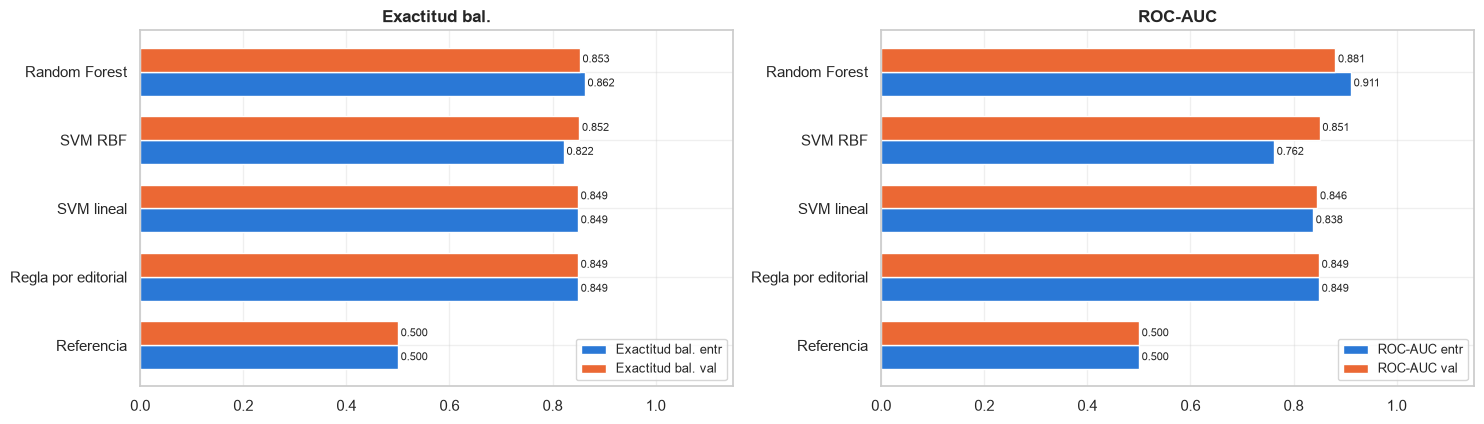

In [36]:
# ============================================================================
#  11.3 Comparación por validación cruzada y elección del modelo
# ============================================================================
tabla_cv3 = pd.DataFrame([fila_cv(n, gs, list(SCORING_3)) for n, gs in busquedas_3.items()]).set_index("Modelo")
display(tabla_cv3[[f"{m} {t}" for m in [METRICA_3, "ROC-AUC", "F1"] for t in ["entr", "val", "±"]]])

GANADOR_3 = elegir_modelo(tabla_cv3, METRICA_3, ["SVM lineal", "SVM RBF", "Random Forest"])
modelo_3 = busquedas_3[GANADOR_3].best_estimator_
print(f"Modelo elegido: {GANADOR_3}")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
for a, m in zip(ax, [METRICA_3, "ROC-AUC"]):
    tabla_cv3[[f"{m} entr", f"{m} val"]].plot.barh(ax=a, color=C_SERIE[:2], width=.7)
    a.set_title(m); a.set_xlim(0, 1.15); a.set_ylabel("")
    for cont in a.containers:
        a.bar_label(cont, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout(); plt.show()

La referencia predice siempre "con ingreso": tiene F1 0.770 pero exactitud balanceada 0.500, lo que muestra por
qué F1 no sirve para seleccionar en este caso. La regla por editorial alcanza una exactitud balanceada de 0.849.

Los tres modelos quedan dentro de un error estándar entre sí (Random Forest 0.853 ± 0.043, SVM RBF 0.852, SVM
lineal 0.849), por lo que se elige el SVM lineal, el más simple. Con C = 0.1 obtiene exactamente el mismo puntaje
que la regla por editorial en entrenamiento y en validación. Ningún modelo supera a la regla por más de 0.004,
una diferencia muy inferior al desvío entre particiones. Random Forest es el que más se ajusta al entrenamiento
(ROC-AUC 0.911 en entrenamiento y 0.881 en validación).

### 11.4 Evaluación en el conjunto de prueba

,SVM lineal,Regla por editorial
Exactitud bal.,0.8780,0.8780
ROC-AUC,0.9159,0.8780
F1,0.8611,0.8611
PR-AUC,0.9610,0.9099
Precisión,1.0000,1.0000
Sensibilidad,0.7561,0.7561
Exactitud,0.8462,0.8462


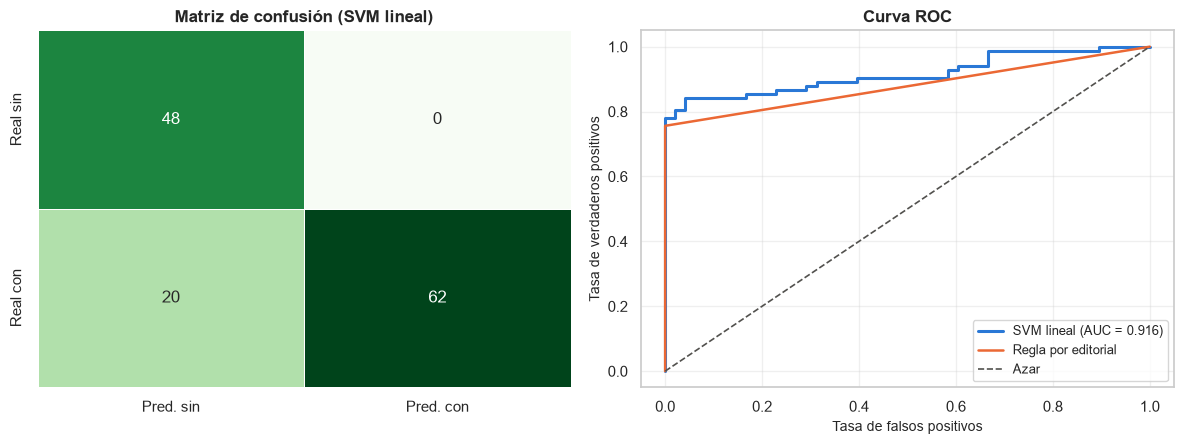

In [37]:
# ============================================================================
#  11.4 Evaluación en el conjunto de prueba
# ============================================================================
def metricas_clasif(y, pred, proba):
    return {"Exactitud bal.": balanced_accuracy_score(y, pred), "ROC-AUC": roc_auc_score(y, proba),
            "F1": f1_score(y, pred), "PR-AUC": average_precision_score(y, proba),
            "Precisión": precision_score(y, pred), "Sensibilidad": recall_score(y, pred),
            "Exactitud": accuracy_score(y, pred)}

proba_te_3 = modelo_3.predict_proba(X_test)[:, 1]
pred_te_3  = modelo_3.predict(X_test)
regla = busquedas_3["Regla por editorial"].best_estimator_
tabla_test_3 = pd.DataFrame({
    GANADOR_3: metricas_clasif(y3_te, pred_te_3, proba_te_3),
    "Regla por editorial": metricas_clasif(y3_te, regla.predict(X_test), regla.predict_proba(X_test)[:, 1]),
})
display(tabla_test_3)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
sns.heatmap(confusion_matrix(y3_te, pred_te_3), annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax[0],
            linewidths=.5, xticklabels=["Pred. sin", "Pred. con"], yticklabels=["Real sin", "Real con"])
ax[0].set_title(f"Matriz de confusión ({GANADOR_3})")
fpr3, tpr3, _ = roc_curve(y3_te, proba_te_3)
ax[1].plot(fpr3, tpr3, lw=2.2, color=C_SERIE[0], label=f"{GANADOR_3} (AUC = {roc_auc_score(y3_te, proba_te_3):.3f})")
fpr_r, tpr_r, _ = roc_curve(y3_te, regla.predict_proba(X_test)[:, 1])
ax[1].plot(fpr_r, tpr_r, lw=1.8, color=C_SERIE[1], label="Regla por editorial")
ax[1].plot([0, 1], [0, 1], ls="--", lw=1.2, color=C_REF, label="Azar")
ax[1].set_xlabel("Tasa de falsos positivos"); ax[1].set_ylabel("Tasa de verdaderos positivos")
ax[1].set_title("Curva ROC"); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

### 11.5 Interpretación y análisis de errores

In [38]:
# ============================================================================
#  11.5 Interpretación y análisis de errores
# ============================================================================
pi_3 = permutation_importance(modelo_3, X_test, y3_te, scoring="balanced_accuracy", n_repeats=20,
                              random_state=RANDOM_STATE, n_jobs=-1)
display(pd.DataFrame({"caída_exactitud_bal": pi_3.importances_mean, "desvío": pi_3.importances_std},
                     index=X_test.columns).sort_values("caída_exactitud_bal", ascending=False))

amazon_tr = X_train["publisher"] == "amazon_digital_services_inc"
print("Títulos de Amazon (entrenamiento): proporción con ingreso por género")
display(y3_tr[amazon_tr].groupby(X_train.loc[amazon_tr, "genre"]).agg(proporcion="mean", libros="size"))
print("Proporción con ingreso por author_rating (entrenamiento):")
display(y3_tr.groupby(X_train["author_rating"]).agg(proporcion="mean", libros="size"))

resultado_3 = pd.DataFrame({
    "editorial": np.where(X_test["publisher"] == "amazon_digital_services_inc", "Amazon", "Otras"),
    "con_ingreso": y3_te.values,
    "predicho_con_ingreso": pred_te_3,
    "acierto_modelo": y3_te.values == pred_te_3,
    "acierto_regla": y3_te.values == regla.predict(X_test),
})
print("Resultados en prueba por tipo de editorial:")
display(resultado_3.groupby("editorial").agg(libros=("con_ingreso", "size"), con_ingreso=("con_ingreso", "mean"),
                                             predicho_con_ingreso=("predicho_con_ingreso", "mean"),
                                             acierto_modelo=("acierto_modelo", "mean"),
                                             acierto_regla=("acierto_regla", "mean")))

,caída_exactitud_bal,desvío
publisher,0.3658,0.0399
author,0.0000,0.0000
author_rating,0.0000,0.0000
genre,0.0000,0.0000
sale_price,0.0000,0.0000
publishing_year,0.0000,0.0000
book_average_rating,0.0000,0.0000
book_ratings_count,0.0000,0.0000


Títulos de Amazon (entrenamiento): proporción con ingreso por género


,proporcion,libros
genre,,
children,1.0000,3
fiction,0.2914,151
non_fiction,0.6250,16


Proporción con ingreso por author_rating (entrenamiento):


,proporcion,libros
author_rating,,
excellent,0.6429,42
famous,0.6667,12
intermediate,0.6134,238
novice,0.8000,10


Resultados en prueba por tipo de editorial:


,libros,con_ingreso,predicho_con_ingreso,acierto_modelo,acierto_regla
editorial,,,,,
Amazon,68,0.2941,0.0000,0.7059,0.7059
Otras,62,1.0000,1.0000,1.0000,1.0000


En el conjunto de prueba, el SVM lineal y la regla por editorial tienen las mismas métricas de clasificación
(exactitud balanceada 0.878, F1 0.861, precisión 1.000, sensibilidad 0.756) porque sus predicciones coinciden en
los 130 libros: el modelo clasifica sin ingreso a todos los títulos de Amazon y con ingreso a los demás. Su
ROC-AUC (0.916) es mayor que el de la regla (0.878), lo que indica que sus puntajes ordenan en parte los títulos
de Amazon, aunque ninguno supera el umbral de decisión.

La importancia por permutación lo confirma: solo `publisher` modifica la exactitud balanceada (caída de 0.37).
Todos los errores son títulos de Amazon con ingreso clasificados sin ingreso (20 de 68). Dentro de Amazon, la
proporción con ingreso es mayor en no ficción (63 %, 16 libros) que en ficción (29 %, 151 libros), pero con tan
pocos casos el modelo regularizado no usa esa diferencia.

Con las variables disponibles, el ingreso editorial se explica por la editorial. Dentro de Amazon depende de algún
factor que el dataset no registra, como el tipo de contrato o el formato.

---
## 12. Predicción sobre títulos nuevos

Se cargan cuatro títulos inventados con las mismas columnas de entrada que `X` y el formato de categorías de
3.3, y se pasan por los tres pipelines finales. Un autor o una editorial no vistos no interrumpen la predicción
(`handle_unknown="ignore"` y media global en la codificación por objetivo); en ese caso, la predicción depende
del resto de los atributos. La segunda tabla indica cuántos libros de entrenamiento comparten cada categoría.

### 12.1 Predicciones y apoyo en los datos de entrenamiento

In [39]:
# ============================================================================
#  12.1 Predicciones y apoyo en los datos de entrenamiento
# ============================================================================
casos_nuevos = pd.DataFrame([
    {"author": "Autora Debutante", "author_rating": "novice", "genre": "fiction",
     "publisher": "amazon_digital_services_inc", "sale_price": 0.99, "publishing_year": 2015,
     "book_average_rating": 3.70, "book_ratings_count": 45000},
    {"author": "Stephen King", "author_rating": "excellent", "genre": "fiction",
     "publisher": "penguin_group_usa_llc", "sale_price": 7.99, "publishing_year": 2011,
     "book_average_rating": 4.10, "book_ratings_count": 160000},
    {"author": "Ensayista", "author_rating": "intermediate", "genre": "non_fiction",
     "publisher": "hachette_book_group", "sale_price": 11.99, "publishing_year": 2013,
     "book_average_rating": 4.30, "book_ratings_count": 60000},
    {"author": "Autor Infantil", "author_rating": "famous", "genre": "children",
     "publisher": "random_house_llc", "sale_price": 4.99, "publishing_year": 1990,
     "book_average_rating": 4.20, "book_ratings_count": 110000},
])[COLUMNAS_ENTRADA]

prob_sv = modelo_1.predict_proba(casos_nuevos)[:, 1]
display(casos_nuevos[["author", "genre", "publisher", "sale_price", "book_ratings_count"]].assign(
    prob_superventas=prob_sv.round(3),
    superventas=np.where(prob_sv >= UMBRAL_1, "sí", "no"),
    unidades_estimadas=np.expm1(modelo_2.predict(casos_nuevos)).round(0),
    prob_ingreso=modelo_3.predict_proba(casos_nuevos)[:, 1].round(3),
    genera_ingreso=np.where(modelo_3.predict(casos_nuevos) == 1, "sí", "no"),
))

print("Libros de entrenamiento con la misma categoría:")
display(pd.DataFrame({
    "autor en entrenamiento": casos_nuevos["author"].isin(X_train["author"]).values,
    "mismo género": casos_nuevos["genre"].map(X_train["genre"].value_counts()).values,
    "mismo author_rating": casos_nuevos["author_rating"].map(X_train["author_rating"].value_counts()).values,
    "misma editorial": casos_nuevos["publisher"].map(X_train["publisher"].value_counts()).values,
}, index=casos_nuevos["author"]))

,author,genre,publisher,sale_price,book_ratings_count,prob_superventas,superventas,unidades_estimadas,prob_ingreso,genera_ingreso
0,Autora Debutante,fiction,amazon_digital_services_inc,0.9900,45000,0.3070,no,101.00,0.3190,no
1,Stephen King,fiction,penguin_group_usa_llc,7.9900,160000,0.7280,sí,960.00,0.9900,sí
2,Ensayista,non_fiction,hachette_book_group,11.9900,60000,0.3100,no,128.00,0.9950,sí
3,Autor Infantil,children,random_house_llc,4.9900,110000,0.0350,no,281.00,0.9970,sí


Libros de entrenamiento con la misma categoría:


,autor en entrenamiento,mismo género,mismo author_rating,misma editorial
author,,,,
Autora Debutante,False,265,10,170
Stephen King,True,265,42,28
Ensayista,False,34,238,16
Autor Infantil,False,3,12,36


El título de Stephen King, el único autor que aparece en entrenamiento, es el único clasificado como superventas
(probabilidad 0.728). Su estimación de 960 unidades queda por debajo del umbral de 1.169: los modelos de los
experimentos 1 y 2 son independientes y, en casos cercanos al umbral, pueden no coincidir. El ensayo de no ficción
con 60.000 calificaciones recibe 128 unidades estimadas, en línea con el peso de `book_ratings_count`. El ingreso
editorial se predice solo según la editorial: sin ingreso para el título de Amazon y con ingreso para los demás.
Para el título infantil hay apenas 3 libros de ese género en entrenamiento, por lo que su predicción depende casi
por completo de las variables numéricas.

---
## 13. Conclusiones

### 13.1 Resumen de resultados

In [40]:
# ============================================================================
#  13.1 Resumen de resultados
# ============================================================================
display(pd.DataFrame([
    {"Experimento": "1. Superventas", "Modelo": "XGBoost", "Métrica": "PR-AUC",
     "Referencia (val.)": tabla_cv1.loc["Referencia", "PR-AUC val"], "Validación cruzada": tabla_cv1.loc["XGBoost", "PR-AUC val"],
     "Prueba": average_precision_score(y1_te, proba_te_1)},
    {"Experimento": "2. Unidades vendidas", "Modelo": GANADOR_2, "Métrica": "RMSE (log)",
     "Referencia (val.)": tabla_cv2.loc["Referencia", "RMSE val"], "Validación cruzada": tabla_cv2.loc[GANADOR_2, "RMSE val"],
     "Prueba": tabla_test_2.loc["RMSE (log)", GANADOR_2]},
    {"Experimento": "3. Ingreso editorial", "Modelo": GANADOR_3, "Métrica": "Exactitud balanceada",
     "Referencia (val.)": tabla_cv3.loc["Referencia", f"{METRICA_3} val"],
     "Validación cruzada": tabla_cv3.loc[GANADOR_3, f"{METRICA_3} val"],
     "Prueba": tabla_test_3.loc[METRICA_3, GANADOR_3]},
]).set_index("Experimento"))

,Modelo,Métrica,Referencia (val.),Validación cruzada,Prueba
Experimento,,,,,
1. Superventas,XGBoost,PR-AUC,0.2052,0.7169,0.7213
2. Unidades vendidas,Ridge,RMSE (log),1.0089,0.5502,0.4516
3. Ingreso editorial,SVM lineal,Exactitud balanceada,0.5000,0.8491,0.8780


### 13.2 Resultados

En el experimento 1, XGBoost identifica el quintil superior de ventas con PR-AUC 0.72 en el conjunto de prueba
(prevalencia 0.20) y ROC-AUC 0.92; con el umbral fijado en entrenamiento detecta 24 de 26 superventas con
precisión 0.59. En el experimento 2, Ridge estima las unidades vendidas con R² 0.70 en validación cruzada (0.80 en
prueba) y un error típico de factor 1.41 (entre −29 % y +41 %); los modelos de boosting no lo superan. En el
experimento 3, ningún modelo supera a la regla por editorial y el modelo elegido reproduce sus predicciones: el
ingreso nulo ocurre solo en Amazon y, dentro de esa editorial, no se explica con las variables disponibles.

### 13.3 Límites

1. Se descartó el 58 % del archivo por inconsistencia contable, y otros indicios (margen editorial de dos
   valores, ranking ordenado según las filas, 20 % de los títulos con 106 a 109 unidades) sugieren que el archivo
   combina fuentes o contiene datos generados. Las conclusiones valen para el bloque A.
2. En los experimentos 1 y 2, `book_ratings_count` explica la mayor parte de la predicción. Sin calificaciones,
   el experimento 1 baja a ROC-AUC 0.60 (9.7).
3. Con 302 libros de entrenamiento y 26 superventas en prueba, las métricas varían bastante: el PR-AUC va de 0.57
   a 0.84 según la partición, y en los experimentos 2 y 3 la prueba resultó más favorable que la validación
   cruzada.
4. El modelo de demanda es casi insensible al precio (|ε| < 0.1) y los datos son observacionales, por lo que no
   permiten recomendar precios.
5. El modelo de demanda sobreestima los títulos de pocas ventas y subestima los de muchas.

### 13.4 Mejoras posibles

Contar con una fuente cuya identidad contable se verifique en todo el catálogo, o documentar el origen del
bloque B. Incorporar variables como el formato (digital o impreso), el tipo de contrato con el canal, las
calificaciones por año desde la publicación (9.6), la pertenencia a una serie o la inversión en marketing. Para
decisiones de lanzamiento, usar información previa a la publicación, como preventas o ventas anteriores del autor.
Para precios, realizar pruebas controladas. En el modelado, calibrar las probabilidades del experimento 1,
estimar intervalos de predicción en el 2 (por ejemplo, con regresión por cuantiles) y repetir la validación
cruzada para reducir la variabilidad de las estimaciones.

### 13.5 Utilidad práctica

El modelo del experimento 1 permite ordenar el catálogo publicado por probabilidad de superventas para decidir
reimpresiones o campañas: en validación cruzada, el 10 % mejor ubicado tiene precisión 0.77 y el 20 % reúne el
58 % de los superventas (9.3). Como la cantidad de calificaciones es pública en plataformas de lectores, el
experimento 2 podría estimar las ventas de títulos sin datos consolidados, siempre que se verifique que
pertenecen a una población similar al bloque A. El experimento 3 indica que el ingreso nulo se concentra en
Amazon, pero identificar su causa requiere información contractual que el dataset no tiene. Cada pipeline recibe
las columnas de entrada de un título nuevo y devuelve la predicción sin pasos manuales (12).

### 13.6 ¿Los modelos funcionan con los datos disponibles al momento de usarlos?

Sí, para títulos ya publicados con calificaciones acumuladas, categorías con el formato de 3.3 y precios entre
USD 1 y 12. No antes del lanzamiento, donde el experimento 1 queda cerca del azar, ni para decidir precios, porque
el modelo de demanda no distingue el efecto del precio.

---
## 14. Anexo

### 14.1 Dataset

*Books Sales and Ratings*, thedevastator, Kaggle:
<https://www.kaggle.com/datasets/thedevastator/books-sales-and-ratings>. Archivo `Books_Data_Clean.csv`
(1.070 filas y 15 columnas, incluida `index`).

### 14.2 Referencias

* Material del curso: *Cuaderno 10: Pipelines y GridSearchCV* (VintaBytes,
  [github.com/VintaBytes/Ciencia-de-datos](https://github.com/VintaBytes/Ciencia-de-datos)) y "Tips para la
  entrega".
* Documentación de scikit-learn: [`Pipeline`](https://scikit-learn.org/stable/modules/compose.html),
  [`ColumnTransformer`](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html),
  [`TargetEncoder`](https://scikit-learn.org/stable/modules/preprocessing.html#target-encoder),
  [`GridSearchCV`](https://scikit-learn.org/stable/modules/grid_search.html),
  [importancia por permutación](https://scikit-learn.org/stable/modules/permutation_importance.html).
* Hastie, T., Tibshirani, R. y Friedman, J. (2009). *The Elements of Statistical Learning*, 2.ª ed., sección 7.10
  (regla de un error estándar). Springer.
* Chen, T. y Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System*. KDD.
* Ke, G. et al. (2017). *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. NeurIPS.
* Lundberg, S. y Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions*. NeurIPS.
* Micci-Barreca, D. (2001). *A Preprocessing Scheme for High-Cardinality Categorical Attributes in
  Classification and Prediction Problems*. SIGKDD Explorations.
* Saito, T. y Rehmsmeier, M. (2015). *The Precision-Recall Plot Is More Informative than the ROC Plot When
  Evaluating Binary Classifiers on Imbalanced Datasets*. PLOS ONE.

### 14.3 Aclaraciones

* Los modelos se entrenan con el bloque A (432 de 1.038 libros después de la limpieza) y las conclusiones valen
  para esa población.
* Se usa la semilla `RANDOM_STATE = 42` en la división, la validación cruzada y los modelos. Con otras versiones
  de las librerías (celda 0.1) los resultados pueden variar levemente.
* `gross_sales`, `publisher_revenue` y `sales_rank` se usan solo para auditar los datos y definir objetivos.
* Algunos títulos conservan caracteres que no pudieron repararse (3.3). No afectan a los modelos porque
  `book_name` no es predictora.
* La simulación de precios (10.7) es observacional, no causal.
* El anexo 14.4 usa datos sintéticos y ninguna conclusión depende de él.

### 14.4 Anexo A: prueba de XGBoost con datos sintéticos

Se verifica si el clasificador recupera una regla conocida: superventas si precio < 20 y calificación > 4.0, con
`book_ratings_count` como variable de ruido. Primero con 10 libros y luego con muestras de distinto tamaño.

#### 14.4.1 Diez observaciones sintéticas

In [41]:
# ============================================================================
#  14.4.1 Diez observaciones sintéticas
# ============================================================================
demo = pd.DataFrame({
    "sale_price"         : [ 12.0,  15.0,   8.0,  45.0,  50.0,  18.0,  30.0,  10.0,  40.0,  22.0],
    "book_average_rating": [  4.5,   4.2,   4.8,   4.9,   3.1,   4.6,   4.4,   3.2,   2.8,   4.7],
    "book_ratings_count" : [ 5000,  3000,  9000,  7000,   400,  6000,  2000,  8000,   300,  1500],
})

def regla_demo(d):
    return ((d["sale_price"] < 20) & (d["book_average_rating"] > 4.0)).astype(int)

y_demo = regla_demo(demo)
modelo_demo = XGBClassifier(objective="binary:logistic", eval_metric="logloss", n_estimators=30,
                            max_depth=2, learning_rate=0.3, scale_pos_weight=(y_demo == 0).sum() / y_demo.sum(),
                            random_state=RANDOM_STATE).fit(demo, y_demo)

nuevos = pd.DataFrame({"sale_price": [14.0, 38.0, 16.0, 12.0],
                       "book_average_rating": [4.7, 4.8, 3.5, 3.4],
                       "book_ratings_count": [4000, 5500, 7000, 2500]})
p_nuevos = modelo_demo.predict_proba(nuevos)[:, 1]
print("Cuatro libros que no están en el entrenamiento:")
display(nuevos.assign(regla=regla_demo(nuevos), prob_predicha=p_nuevos.round(3),
                      prediccion=(p_nuevos >= 0.5).astype(int)))
print("Importancia de cada variable:", pd.Series(modelo_demo.feature_importances_, index=demo.columns).round(4).to_dict())

Cuatro libros que no están en el entrenamiento:

,sale_price,book_average_rating,book_ratings_count,regla,prob_predicha,prediccion
0,14.0000,4.7000,4000,1,0.8130,1
1,38.0000,4.8000,5500,0,0.2230,0
2,16.0000,3.5000,7000,0,0.6930,1
3,12.0000,3.4000,2500,0,0.6930,1


Importancia de cada variable: {'sale_price': 0.7301999926567078, 'book_average_rating': 0.26980000734329224, 'book_ratings_count': 0.0}


#### 14.4.2 Acierto según el tamaño de la muestra

Acierto sobre 4.000 casos nuevos (promedio de 5 semillas):


filas de entrenamiento,10,20,30,50,80,120,200,400,800
acierto %,84.9438,86.4450,97.4450,96.4700,97.4500,99.4400,98.9100,99.6700,99.8850


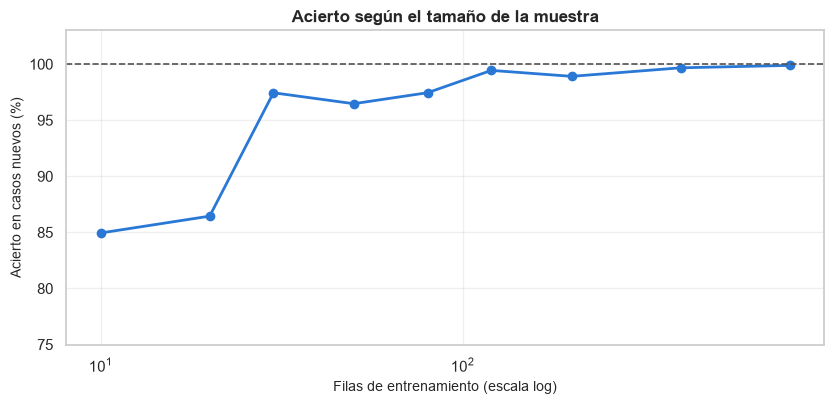

In [42]:
# ============================================================================
#  14.4.2 Acierto según el tamaño de la muestra
# ============================================================================
def acierto_con_n(n, semilla):
    rg = np.random.default_rng(semilla)
    d = pd.DataFrame({"sale_price": rg.uniform(5, 55, n).round(2),
                      "book_average_rating": rg.uniform(2.5, 5.0, n).round(2),
                      "book_ratings_count": rg.integers(200, 9000, n)})
    yy = regla_demo(d)
    if yy.nunique() < 2:
        return np.nan
    mm = XGBClassifier(objective="binary:logistic", eval_metric="logloss", n_estimators=30, max_depth=2,
                       learning_rate=0.3, scale_pos_weight=(yy == 0).sum() / yy.sum(),
                       random_state=RANDOM_STATE).fit(d, yy)
    rv = np.random.default_rng(999)
    t = pd.DataFrame({"sale_price": rv.uniform(5, 55, 4000).round(2),
                      "book_average_rating": rv.uniform(2.5, 5.0, 4000).round(2),
                      "book_ratings_count": rv.integers(200, 9000, 4000)})
    return float(((mm.predict_proba(t)[:, 1] >= .5).astype(int) == regla_demo(t)).mean())

TAMANOS = [10, 20, 30, 50, 80, 120, 200, 400, 800]
curva = pd.Series([100 * np.nanmean([acierto_con_n(n, s) for s in range(5)]) for n in TAMANOS],
                  index=pd.Index(TAMANOS, name="filas de entrenamiento"), name="acierto %")
print("Acierto sobre 4.000 casos nuevos (promedio de 5 semillas):")
display(curva.to_frame().T)

plt.figure(figsize=(8.5, 4.2))
plt.plot(curva.index, curva.values, "o-", lw=2, color=C_SERIE[0], markersize=6)
plt.axhline(100, color=C_REF, ls="--", lw=1.2)
plt.xscale("log"); plt.ylim(75, 103)
plt.xlabel("Filas de entrenamiento (escala log)"); plt.ylabel("Acierto en casos nuevos (%)")
plt.title("Acierto según el tamaño de la muestra")
plt.tight_layout(); plt.show()

El modelo clasifica bien los dos libros que se resuelven por el precio (USD 14 con calificación 4.7, y USD 38),
pero clasifica como superventas los dos baratos con calificación baja (USD 16 con 3.5 y USD 12 con 3.4), con
probabilidad 0.69. Aproximó la regla como "precio < 20" y usa la calificación solo en parte (importancia 0.27).
`book_ratings_count`, que no interviene en la regla, tiene importancia 0.

Entre las 10 filas hay un único libro barato con calificación baja (USD 10 y 3.2). Con `min_child_weight = 1`,
cada hoja necesita una suma de hessianos de al menos 1, lo que equivale a unas cuatro observaciones con
probabilidad cercana a 0.5, de modo que el árbol no puede aislar ese caso.

El acierto sobre casos nuevos es de 85 % con 10 filas y 86 % con 20, sube a 97 % con 30 y se mantiene cerca de
99 % desde 120: la regla se recupera cuando la muestra incluye suficientes casos de la combinación que la define.
En el dataset real, las categorías con pocos libros, como los 3 títulos infantiles de entrenamiento, están en una
situación parecida y sus predicciones son menos confiables.